## Preparations for Google Colab

In [1]:
# needed packages
#!pip install -q RDKit pyarrow>=13.0.0
#pip3 install pandas==3.0.3
#!pip install lifelines

#from google.colab import drive
#drive.mount('/content/drive', force_remount=True)

## Preparation

In [2]:
%pip install torch-geometric

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
import torch.nn as nn
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, root_mean_squared_error, silhouette_score
from sklearn.metrics import mean_absolute_error
from scipy.stats import pearsonr, spearmanr
#from lifelines.utils import concordance_index
from sklearn.model_selection import GroupShuffleSplit, train_test_split
import pandas as pd
import sys
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform
import seaborn as sns
from rdkit import Chem
from torch_geometric.data import Data
sys.path.append('/content/drive/MyDrive')
from gnn_models_utils import (
    DrugResponseDataset,
    EarlyStopping,
    build_pyg_dataset,
    smiles_to_graph,
    weighted_mse_loss,
    set_seed,
    GroundedCrossAttentionModel,
    GCNDrugEncoder,
    #GATDrugEncoder,
    #GINDrugEncoder
)
from tqdm.auto import tqdm
import os
from pathlib import Path
molclr_path = os.path.abspath('../MolCLR')
if molclr_path not in sys.path:
    sys.path.append(molclr_path)
from models.gcn_molclr import GCN
from models.ginet_molclr import GINet
sys.path.append(str(Path.cwd().parent))
from configs.config import HARMONIZED_DATA_PATH

In [108]:
df = pd.read_parquet(HARMONIZED_DATA_PATH)
print(f"Data set successfully loaded: {df.shape}")

Data set successfully loaded: (144082, 2024)


In [5]:
#df.to_parquet("/content/drive/MyDrive/datasets/harmonized_data_2292026_rightSMILES.parquet")

## Check dataset

In [6]:
'''import re
other_cols = [
    col for col in df.columns
    if not col.startswith('Bit_') and not re.match(r'.* \(\d+\)', col)
]

print(f"Columns found ({len(other_cols)}):")
for col in other_cols:
    print(col)'''

<>:4: SyntaxWarning: invalid escape sequence '\('
<>:4: SyntaxWarning: invalid escape sequence '\('
/var/folders/vr/kvp0z9ld38j_hy0jr6hvmlj40000gn/T/ipykernel_63238/1353852994.py:4: SyntaxWarning: invalid escape sequence '\('
  if not col.startswith('Bit_') and not re.match(r'.* \(\d+\)', col)


'import re\nother_cols = [\n    col for col in df.columns\n    if not col.startswith(\'Bit_\') and not re.match(r\'.* \\(\\d+\\)\', col)\n]\n\nprint(f"Columns found ({len(other_cols)}):")\nfor col in other_cols:\n    print(col)'

In [7]:
# Check the sample for known active ingredients
'''test_drugs = ['Paclitaxel', 'Cisplatin', 'Doxorubicin', 'Gefitinib']
check_df = df[df['DRUG_NAME'].isin(test_drugs)][['DRUG_ID', 'DRUG_NAME', 'SMILES']].drop_duplicates()
print(check_df)'''

"test_drugs = ['Paclitaxel', 'Cisplatin', 'Doxorubicin', 'Gefitinib']\ncheck_df = df[df['DRUG_NAME'].isin(test_drugs)][['DRUG_ID', 'DRUG_NAME', 'SMILES']].drop_duplicates()\nprint(check_df)"

In [8]:
'''print(df['CANCER_TYPE'].unique())'''

"print(df['CANCER_TYPE'].unique())"

## Training data

In [9]:
'''# training data group split in train val
target = 'LN_IC50'
pharmacophores = ['Donor', 'Acceptor', 'Aromatic', 'Hydrophobe', 'LumpedHydrophobe', 'PosIonizable', 'NegIonizable', 'ZnBinder']
mfp_cols = [col for col in df.columns if col.startswith('Bit_')]
X_genomic = df.filter(regex=r'.* \(.*\)').values.astype('float32')
X_chem = df[pharmacophores + mfp_cols]
y = df[target].values.astype('float32')

# split data into train and test
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=6726)
idx_train_val, idx_test = next(gss_test.split(X_genomic, y, groups=df['DRUG_ID']))

# separate validation set from training set
groups_train_val = df['DRUG_ID'].iloc[idx_train_val]
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.11, random_state=42)
idx_train, idx_val = next(gss_val.split(X_genomic[idx_train_val], y[idx_train_val], groups=groups_train_val))

idx_train = idx_train_val[idx_train]
idx_val = idx_train_val[idx_val]

preprocessor = ColumnTransformer(
    transformers=[
        ('pharmacophore', StandardScaler(), pharmacophores),
        #('mfp', PCA(n_components=50, random_state=42), mfp_cols)
        ('mfp', 'passthrough', mfp_cols)
    ],
    remainder='drop'
)
gene_scaler = StandardScaler()

X_genomic_train = gene_scaler.fit_transform(X_genomic[idx_train])
X_chem_train = preprocessor.fit_transform(X_chem.iloc[idx_train])

X_genomic_val = gene_scaler.transform(X_genomic[idx_val])
X_chem_val = preprocessor.transform(X_chem.iloc[idx_val])

X_genomic_test = gene_scaler.transform(X_genomic[idx_test])
X_chem_test = preprocessor.transform(X_chem.iloc[idx_test])

# scale IC50 values
#scaler = StandardScaler()
y_train = y[idx_train]#scaler.fit_transform(y[idx_train].reshape(-1, 1)).flatten()
y_val = y[idx_val]#scaler.transform(y[idx_val].reshape(-1, 1)).flatten()
y_test = y[idx_test]#scaler.transform(y[idx_test].reshape(-1, 1)).flatten()'''

<>:5: SyntaxWarning: invalid escape sequence '\('
<>:5: SyntaxWarning: invalid escape sequence '\('
/var/folders/vr/kvp0z9ld38j_hy0jr6hvmlj40000gn/T/ipykernel_63238/1538051907.py:5: SyntaxWarning: invalid escape sequence '\('
  X_genomic = df.filter(regex=r'.* \(.*\)').values.astype('float32')


"# training data group split in train val\ntarget = 'LN_IC50'\npharmacophores = ['Donor', 'Acceptor', 'Aromatic', 'Hydrophobe', 'LumpedHydrophobe', 'PosIonizable', 'NegIonizable', 'ZnBinder']\nmfp_cols = [col for col in df.columns if col.startswith('Bit_')]\nX_genomic = df.filter(regex=r'.* \\(.*\\)').values.astype('float32')\nX_chem = df[pharmacophores + mfp_cols]\ny = df[target].values.astype('float32')\n\n# split data into train and test\ngss_test = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=6726)\nidx_train_val, idx_test = next(gss_test.split(X_genomic, y, groups=df['DRUG_ID']))\n\n# separate validation set from training set\ngroups_train_val = df['DRUG_ID'].iloc[idx_train_val]\ngss_val = GroupShuffleSplit(n_splits=1, test_size=0.11, random_state=42)\nidx_train, idx_val = next(gss_val.split(X_genomic[idx_train_val], y[idx_train_val], groups=groups_train_val))\n\nidx_train = idx_train_val[idx_train]\nidx_val = idx_train_val[idx_val]\n\npreprocessor = ColumnTransformer

In [10]:
'''def make_loaders(batch_size=128, seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

    g = torch.Generator()
    g.manual_seed(seed)

    train_loader = DataLoader(
        DrugResponseDataset(X_genomic_train, X_chem_train, y_train),
        batch_size=batch_size,
        shuffle=True,
        drop_last=True,
        generator=g,
    )
    val_loader = DataLoader(
        DrugResponseDataset(X_genomic_val, X_chem_val, y_val),
        batch_size=batch_size,
        shuffle=False,
    )
    test_loader = DataLoader(
        DrugResponseDataset(X_genomic_test, X_chem_test, y_test),
        batch_size=batch_size,
        shuffle=False,
    )
    return train_loader, val_loader, test_loader

class DrugResponseDataset(Dataset):
    def __init__(self, X_gen, X_ch, labels):
        self.X_genomic = torch.tensor(X_gen, dtype=torch.float32)
        self.X_chem = torch.tensor(X_ch if isinstance(X_ch, np.ndarray) else X_ch.values, dtype=torch.float32)
        self.y = torch.tensor(labels, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X_genomic[idx], self.X_chem[idx], self.y[idx]'''

'def make_loaders(batch_size=128, seed=42):\n    torch.manual_seed(seed)\n    np.random.seed(seed)\n    random.seed(seed)\n\n    g = torch.Generator()\n    g.manual_seed(seed)\n\n    train_loader = DataLoader(\n        DrugResponseDataset(X_genomic_train, X_chem_train, y_train),\n        batch_size=batch_size,\n        shuffle=True,\n        drop_last=True,\n        generator=g,\n    )\n    val_loader = DataLoader(\n        DrugResponseDataset(X_genomic_val, X_chem_val, y_val),\n        batch_size=batch_size,\n        shuffle=False,\n    )\n    test_loader = DataLoader(\n        DrugResponseDataset(X_genomic_test, X_chem_test, y_test),\n        batch_size=batch_size,\n        shuffle=False,\n    )\n    return train_loader, val_loader, test_loader\n\nclass DrugResponseDataset(Dataset):\n    def __init__(self, X_gen, X_ch, labels):\n        self.X_genomic = torch.tensor(X_gen, dtype=torch.float32)\n        self.X_chem = torch.tensor(X_ch if isinstance(X_ch, np.ndarray) else X_ch.values, 

## Different ways to cluster genes

### Similarity of distances of expression profiles, fixed amount of clusters

In [11]:
'''import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import pdist

gene_feature_names = df.filter(regex=r'.* \(.*\)').columns.tolist()

# correlation matrix for genomic features
X_genomic = df.filter(regex=r'.* \(.*\)').values.astype('float32')
gene_corr = np.corrcoef(X_genomic.T)  # (978, 978)

# distance matrix and ward-linkage
dist_matrix = np.clip(1.0 - gene_corr, 0, 2)
np.fill_diagonal(dist_matrix, 0)
condensed_dist = pdist(dist_matrix)
linkage_matrix = linkage(condensed_dist, method='ward')

# cut into X clusters (tokens)
num_tokens = 32
gene_clusters = fcluster(linkage_matrix, t=32, criterion='maxclust') - 1

gene_token_indices = [np.where(gene_clusters == i)[0] for i in range(num_tokens)]
for i, indices in enumerate(gene_token_indices):
    print(f"Gene Token {i}: {len(indices)} genes assigned")'''

<>:6: SyntaxWarning: invalid escape sequence '\('
<>:6: SyntaxWarning: invalid escape sequence '\('
/var/folders/vr/kvp0z9ld38j_hy0jr6hvmlj40000gn/T/ipykernel_63238/941915411.py:6: SyntaxWarning: invalid escape sequence '\('
  gene_feature_names = df.filter(regex=r'.* \(.*\)').columns.tolist()


'import numpy as np\nimport pandas as pd\nfrom scipy.cluster.hierarchy import fcluster, linkage\nfrom scipy.spatial.distance import pdist\n\ngene_feature_names = df.filter(regex=r\'.* \\(.*\\)\').columns.tolist()\n\n# correlation matrix for genomic features\nX_genomic = df.filter(regex=r\'.* \\(.*\\)\').values.astype(\'float32\')\ngene_corr = np.corrcoef(X_genomic.T)  # (978, 978)\n\n# distance matrix and ward-linkage\ndist_matrix = np.clip(1.0 - gene_corr, 0, 2)\nnp.fill_diagonal(dist_matrix, 0)\ncondensed_dist = pdist(dist_matrix)\nlinkage_matrix = linkage(condensed_dist, method=\'ward\')\n\n# cut into X clusters (tokens)\nnum_tokens = 32\ngene_clusters = fcluster(linkage_matrix, t=32, criterion=\'maxclust\') - 1\n\ngene_token_indices = [np.where(gene_clusters == i)[0] for i in range(num_tokens)]\nfor i, indices in enumerate(gene_token_indices):\n    print(f"Gene Token {i}: {len(indices)} genes assigned")'

### Similarity of expression profiles, fixed amount of clusters

In [12]:
'''from scipy.cluster.hierarchy import linkage, fcluster
from scipy.stats import zscore

X_genes = X_genomic.T
X_genes = zscore(X_genes, axis=1)

Z = linkage(X_genes, method="ward", metric="euclidean")
gene_clusters = fcluster(Z, t=32, criterion="maxclust") - 1
num_tokens = 32
gene_token_indices = [
    np.where(gene_clusters == label)[0]
    for label in np.unique(gene_clusters)
]

for i, indices in enumerate(gene_token_indices):
    print(f"Gene Token {i}: {len(indices)} genes assigned")'''

'from scipy.cluster.hierarchy import linkage, fcluster\nfrom scipy.stats import zscore\n\nX_genes = X_genomic.T\nX_genes = zscore(X_genes, axis=1)\n\nZ = linkage(X_genes, method="ward", metric="euclidean")\ngene_clusters = fcluster(Z, t=32, criterion="maxclust") - 1\nnum_tokens = 32\ngene_token_indices = [\n    np.where(gene_clusters == label)[0]\n    for label in np.unique(gene_clusters)\n]\n\nfor i, indices in enumerate(gene_token_indices):\n    print(f"Gene Token {i}: {len(indices)} genes assigned")'

### Cancer type
Each gene is assigned to the cancer type token for which it exhibits the highest specific upregulation (maximum Z-score) compared to all other cancer types.

In [13]:
'''gene_cols = df.filter(regex=r'.* \(.*\)').columns.tolist()
X_genes = df[gene_cols].values
cancer_types = df['CANCER_TYPE'].values
unique_cancer_types = df['CANCER_TYPE'].unique()

mean_expr = np.array([X_genes[cancer_types == ct].mean(axis=0) for ct in unique_cancer_types])
mean_expr_z = (mean_expr - mean_expr.mean(axis=0)) / (mean_expr.std(axis=0) + 1e-8)
gene_assignments = np.argmax(mean_expr_z, axis=0)

gene_token_indices = []
active_labels = []

for ct_idx, ct_name in enumerate(unique_cancer_types):
    idx = np.where(gene_assignments == ct_idx)[0]
    if len(idx) > 0:
        gene_token_indices.append(idx)
        active_labels.append(ct_name)
        print(f"Token {len(gene_token_indices)-1} ({ct_name}): {len(idx)} genes")'''

<>:1: SyntaxWarning: invalid escape sequence '\('
<>:1: SyntaxWarning: invalid escape sequence '\('
/var/folders/vr/kvp0z9ld38j_hy0jr6hvmlj40000gn/T/ipykernel_63238/3211959562.py:1: SyntaxWarning: invalid escape sequence '\('
  '''gene_cols = df.filter(regex=r'.* \(.*\)').columns.tolist()


'gene_cols = df.filter(regex=r\'.* \\(.*\\)\').columns.tolist()\nX_genes = df[gene_cols].values\ncancer_types = df[\'CANCER_TYPE\'].values\nunique_cancer_types = df[\'CANCER_TYPE\'].unique()\n\nmean_expr = np.array([X_genes[cancer_types == ct].mean(axis=0) for ct in unique_cancer_types])\nmean_expr_z = (mean_expr - mean_expr.mean(axis=0)) / (mean_expr.std(axis=0) + 1e-8)\ngene_assignments = np.argmax(mean_expr_z, axis=0)\n\ngene_token_indices = []\nactive_labels = []\n\nfor ct_idx, ct_name in enumerate(unique_cancer_types):\n    idx = np.where(gene_assignments == ct_idx)[0]\n    if len(idx) > 0:\n        gene_token_indices.append(idx)\n        active_labels.append(ct_name)\n        print(f"Token {len(gene_token_indices)-1} ({ct_name}): {len(idx)} genes")'

### Adapted WGCNA
Co-expression modules as network groups. TOM also takes into account whether two genes have similar network neighbors.

In [86]:
import numpy as np
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

# pearson correlation
X_genomic = df.filter(regex=r'.* \(.*\)').values.astype('float32')
corr_matrix = np.corrcoef(X_genomic.T)

# Soft Thresholding (Create Adjacency Matrix)
# beta=6 is the standard bioinformatics value, to suppress weak noise and highlight strong signaling pathways.
beta = 6
# positive and negative correlations are treated equally, as they both indicate a relationship between genes.
adj_matrix = np.abs(corr_matrix) ** beta 

# Calculate the Topological Overlap Measure (TOM)
# Matrix multiplication identifies the shared neighborhoods (signal pathways)
l_matrix = np.dot(adj_matrix, adj_matrix)

# Sum of connection strengths per gene (Connectivity)
k = np.sum(adj_matrix, axis=1)
k_min_matrix = np.minimum.outer(k, k)

# WGCNA TOM Formula
tom_matrix = (l_matrix + adj_matrix) / (k_min_matrix + 1.0 - adj_matrix)
np.fill_diagonal(tom_matrix, 1.0)

# Convert to a dissimilarity matrix
dist_matrix = 1.0 - tom_matrix
# Handle rounding errors and set the diagonal to 0
dist_matrix = np.clip(dist_matrix, 0.0, 1.0)
np.fill_diagonal(dist_matrix, 0.0)

condensed_dist = squareform(dist_matrix, checks=False)
Z = linkage(condensed_dist, method='average')

cut_height = 0.995 # fixed so we don't get 0 clusters
labels = fcluster(Z, t=cut_height, criterion='distance')
min_module_size = 20
unique_labels, counts = np.unique(labels, return_counts=True)

valid_clusters = unique_labels[counts >= min_module_size]

gene_token_indices = []
noise_genes = []

for cluster_id in unique_labels:
    indices = np.where(labels == cluster_id)[0]
    if cluster_id in valid_clusters:
        gene_token_indices.append(indices)
    else:
        noise_genes.extend(indices)

print(f"Optimal number of tokens found: {len(gene_token_indices)}")
for i, indices in enumerate(gene_token_indices):
    print(f"Gene Token {i} (WGCNA module): {len(indices)} genes assigned")

print(f"Ignored noise genes (grey module): {len(noise_genes)} genes")

Optimal number of tokens found: 3
Gene Token 0 (WGCNA module): 22 genes assigned
Gene Token 1 (WGCNA module): 115 genes assigned
Gene Token 2 (WGCNA module): 127 genes assigned
Ignored noise genes (grey module): 714 genes


#### Define cut height

In [64]:
for height in [0.90, 0.95, 0.98, 0.99, 0.992, 0.995, 0.999]:
    labels = fcluster(Z, t=height, criterion="distance")
    _, sizes = np.unique(labels, return_counts=True)

    retained = sizes[sizes >= min_module_size]
    print(
        f"cut={height:.3f}: "
        f"{len(sizes)} Cluster insgesamt, "
        f"{len(retained)} Module >= {min_module_size} Gene, "
        f"{len(sizes) - len(retained)} kleine Cluster"
    )

cut=0.900: 927 Cluster insgesamt, 0 Module >= 20 Gene, 927 kleine Cluster
cut=0.950: 820 Cluster insgesamt, 0 Module >= 20 Gene, 820 kleine Cluster
cut=0.980: 622 Cluster insgesamt, 2 Module >= 20 Gene, 620 kleine Cluster
cut=0.990: 490 Cluster insgesamt, 3 Module >= 20 Gene, 487 kleine Cluster
cut=0.992: 450 Cluster insgesamt, 3 Module >= 20 Gene, 447 kleine Cluster
cut=0.995: 360 Cluster insgesamt, 3 Module >= 20 Gene, 357 kleine Cluster
cut=0.999: 149 Cluster insgesamt, 5 Module >= 20 Gene, 144 kleine Cluster


In [65]:
import numpy as np
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

def make_wgcna_modules(
    X_genomic_train,
    cut_height,
    beta=6,
    min_module_size=20,
):
    # Samples in Zeilen, Gene in Spalten
    if not np.isfinite(X_genomic_train).all():
        raise ValueError("X_genomic_train enthält NaN oder inf.")

    # Konstante Gene können keine Korrelation liefern
    variable_mask = X_genomic_train.std(axis=0) > 0
    original_gene_indices = np.flatnonzero(variable_mask)
    X = X_genomic_train[:, variable_mask]

    if X.shape[1] < 2:
        raise ValueError("Für das Clustering werden mindestens 2 variable Gene benötigt.")

    corr = np.corrcoef(X.T)

    # Unsigned adjacency: positive und negative Korrelationen zählen gleich
    adjacency = np.abs(corr) ** beta

    # Keine Selbstverbindungen in die Konnektivität einrechnen
    np.fill_diagonal(adjacency, 0.0)

    shared_neighbors = adjacency @ adjacency
    connectivity = adjacency.sum(axis=1)
    min_connectivity = np.minimum.outer(connectivity, connectivity)

    tom = (shared_neighbors + adjacency) / (
        min_connectivity + 1.0 - adjacency
    )
    np.fill_diagonal(tom, 1.0)

    distance = np.clip(1.0 - tom, 0.0, 1.0)
    np.fill_diagonal(distance, 0.0)

    tree = linkage(squareform(distance, checks=False), method="average")
    labels = fcluster(tree, t=cut_height, criterion="distance")

    modules = []
    for label in np.unique(labels):
        local_indices = np.flatnonzero(labels == label)
        if len(local_indices) >= min_module_size:
            # Indizes zurück auf die ursprünglichen Gen-Spalten beziehen
            modules.append(original_gene_indices[local_indices])

    return modules

cut=0.9: übersprungen (0 Module)
cut=0.95: übersprungen (0 Module)

Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


EarlyStopping counter: 4 out of 10


EarlyStopping counter: 5 out of 10


EarlyStopping counter: 6 out of 10


EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


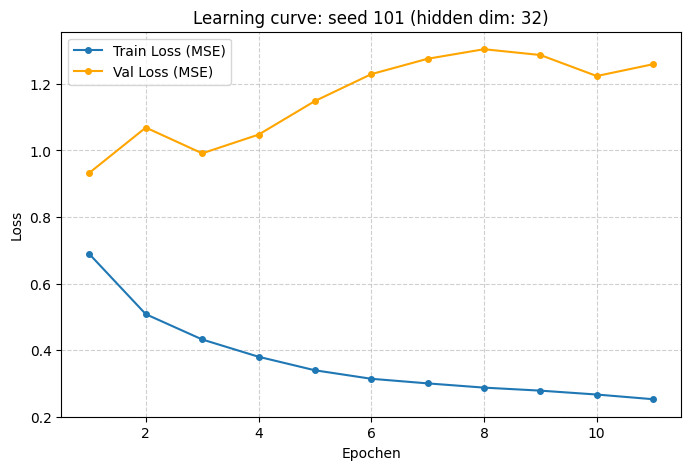

--> Result Seed 101: Best Epoch: 01 | Val Loss: 0.9331 | Test RMSE: 2.0806 | Test R²: 0.5104

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           1  0.933085    2.08055  0.51038  1.694474           0.719273             0.59105

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.0806 ± nan
Test R²:   0.5104 ± nan
Test Spearman coefficient: 0.5910 ± nan
Test Pearson coefficient: 0.7193 ± nan
Test mean absolute error: 1.6945 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


EarlyStopping counter: 4 out of 10


EarlyStopping counter: 5 out of 10


EarlyStopping counter: 6 out of 10


EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


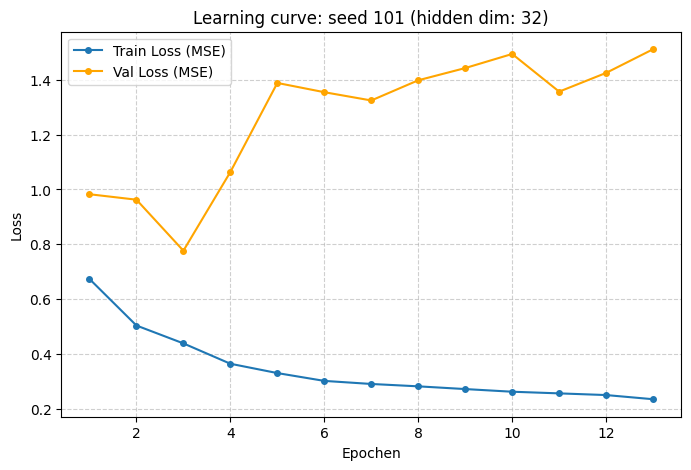

--> Result Seed 101: Best Epoch: 03 | Val Loss: 0.7768 | Test RMSE: 2.1580 | Test R²: 0.4732

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           3  0.776799   2.158036 0.473231  1.646679            0.74693            0.643145

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.1580 ± nan
Test R²:   0.4732 ± nan
Test Spearman coefficient: 0.6431 ± nan
Test Pearson coefficient: 0.7469 ± nan
Test mean absolute error: 1.6467 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


EarlyStopping counter: 4 out of 10


... (2 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


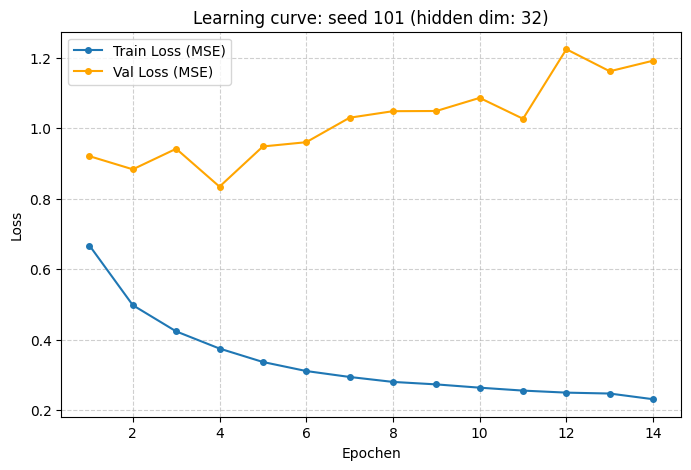

--> Result Seed 101: Best Epoch: 04 | Val Loss: 0.8338 | Test RMSE: 1.9809 | Test R²: 0.5562

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           4  0.833793   1.980874  0.55617  1.596157           0.759361            0.624931

--- Aggregated metrics (mean ± std) ---
Test RMSE: 1.9809 ± nan
Test R²:   0.5562 ± nan
Test Spearman coefficient: 0.6249 ± nan
Test Pearson coefficient: 0.7594 ± nan
Test mean absolute error: 1.5962 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


... (4 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


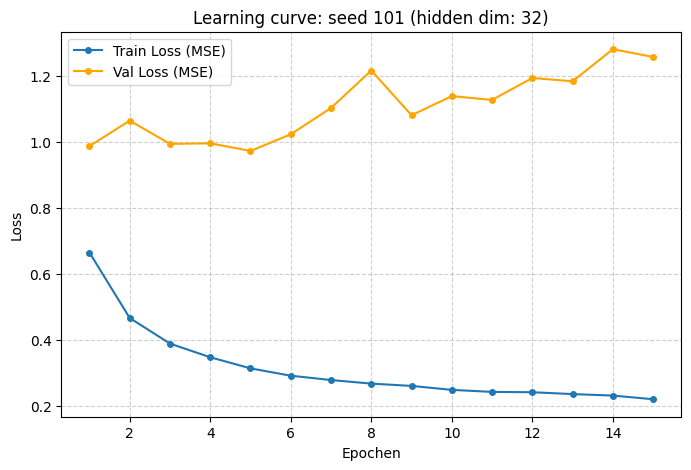

--> Result Seed 101: Best Epoch: 05 | Val Loss: 0.9729 | Test RMSE: 2.2036 | Test R²: 0.4507

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           5  0.972873   2.203642 0.450731  1.748277           0.677207            0.588788

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.2036 ± nan
Test R²:   0.4507 ± nan
Test Spearman coefficient: 0.5888 ± nan
Test Pearson coefficient: 0.6772 ± nan
Test mean absolute error: 1.7483 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


EarlyStopping counter: 4 out of 10


... (2 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


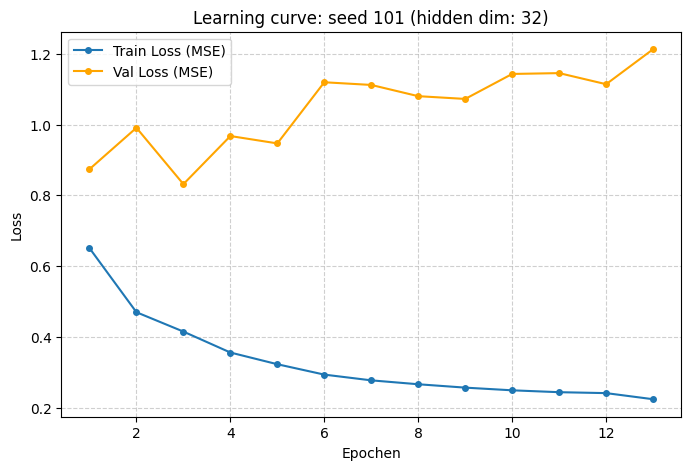

--> Result Seed 101: Best Epoch: 03 | Val Loss: 0.8317 | Test RMSE: 2.1518 | Test R²: 0.4763

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           3  0.831738   2.151762 0.476289  1.673419           0.776811             0.65101

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.1518 ± nan
Test R²:   0.4763 ± nan
Test Spearman coefficient: 0.6510 ± nan
Test Pearson coefficient: 0.7768 ± nan
Test mean absolute error: 1.6734 ± nan


cut=0.995 | Module=3 | Val MSE=0.9729 ± 0.0000 | Größen=[21, 124, 128]
cut=0.980 | Module=2 | Val MSE=0.9331 ± 0.0000 | Größen=[48, 31]
cut=0.992 | Module=3 | Val MSE=0.8338 ± 0.0000 | Größen=[92, 24, 71]
cut=0.999 | Module=4 | Val MSE=0.8317 ± 0.0000 | Größen=[252, 20, 262, 25]
cut=0.990 | Module=2 | Val MSE=0.7768 ± 0.0000 | Größen=[73, 67]

Ausgewählt: cut_height=0.995, 3 Module, mittleres Val-MSE=0.9729


In [75]:
cut_heights = [0.90, 0.95, 0.98, 0.99, 0.992, 0.995, 0.999]
seeds_for_selection = [101]

results = []

for cut_height in cut_heights:
    modules = make_wgcna_modules(
        X_genomic_train=X_gen_train,
        cut_height=cut_height,
        beta=6,
        min_module_size=20,
    )

    # Kandidaten ohne mindestens zwei brauchbare Module überspringen
    if len(modules) < 2:
        print(f"cut={cut_height}: übersprungen ({len(modules)} Module)")
        continue
    

    val_mse_scores = []

    for seed in seeds_for_selection:
        # Diese Funktion enthält deinen vorhandenen Modell-/Trainingscode.
        # Sie muss ein neues Modell initialisieren, trainieren und
        # das Validierungs-MSE zurückgeben.
        val_mse = fit_and_score(gene_token_indices=modules)
        val_mse_scores.append(val_mse)

    results.append({
        "cut_height": cut_height,
        "n_modules": len(modules),
        "val_mse_mean": float(np.mean(val_mse_scores)),
        "val_mse_std": float(np.std(val_mse_scores)),
        "module_sizes": [len(module) for module in modules],
        "gene_token_indices": modules,
    })

results.sort(key=lambda result: result["val_mse_mean"], reverse=True)

for result in results:
    print(
        f"cut={result['cut_height']:.3f} | "
        f"Module={result['n_modules']} | "
        f"Val MSE={result['val_mse_mean']:.4f} "
        f"± {result['val_mse_std']:.4f} | "
        f"Größen={result['module_sizes']}"
    )

best = results[0]
best_cut_height = best["cut_height"]
best_gene_token_indices = best["gene_token_indices"]

print(
    f"\nAusgewählt: cut_height={best_cut_height}, "
    f"{best['n_modules']} Module, "
    f"mittleres Val-MSE={best['val_mse_mean']:.4f}"
)

#### Use optuna to find cut height + min module size 

In [79]:
def objective(trial):
    cut_height = trial.suggest_categorical(
        "cut_height", [0.90, 0.95, 0.98, 0.99, 0.992, 0.995, 0.999]
    )
    min_module_size = trial.suggest_categorical(
        "min_module_size", [10, 20, 30]
    )

    modules = make_wgcna_modules(
        X_genomic_train=X_gen_train,
        cut_height=cut_height,
        beta=6,
        min_module_size=min_module_size,
    )

    # Dein Modell braucht mindestens zwei Gen-Tokens.
    if len(modules) < 2:
        raise optuna.TrialPruned()

    # Erst wenige Seeds für die Suche; dieselben Seeds für jeden Trial verwenden.
    seed_scores = []
    best_val_mse = fit_and_score(
        gene_token_indices=modules
    )
    seed_scores.append(best_val_mse)

    mean_val_mse = float(np.mean(seed_scores))
    trial.set_user_attr("n_modules", len(modules))
    trial.set_user_attr("module_sizes", [len(module) for module in modules])

    return mean_val_mse

[I 2026-11-12 13:53:22,609] A new study created in memory with name: no-name-467dec31-fff8-40a7-9c6f-29503e4e643c



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


... (10 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


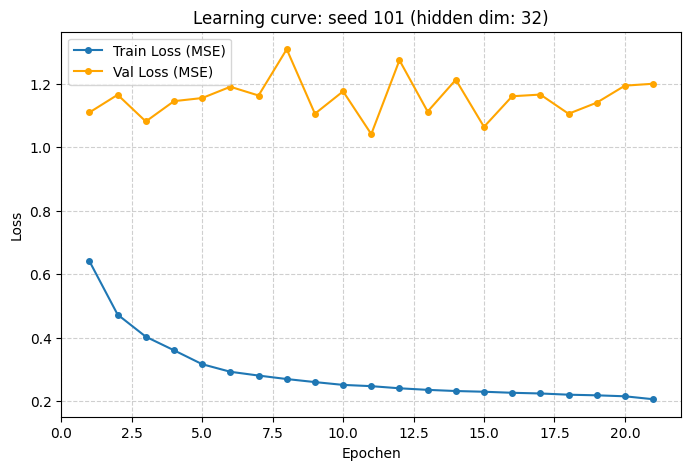

[I 2026-11-12 14:10:50,551] Trial 0 finished with value: 1.0417944689612644 and parameters: {'cut_height': 0.992, 'min_module_size': 10}. Best is trial 0 with value: 1.0417944689612644.


--> Result Seed 101: Best Epoch: 11 | Val Loss: 1.0418 | Test RMSE: 2.4228 | Test R²: 0.3361

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101          11  1.041794   2.422761 0.336067  1.923365           0.608346            0.493024

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.4228 ± nan
Test R²:   0.3361 ± nan
Test Spearman coefficient: 0.4930 ± nan
Test Pearson coefficient: 0.6083 ± nan
Test mean absolute error: 1.9234 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


... (3 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


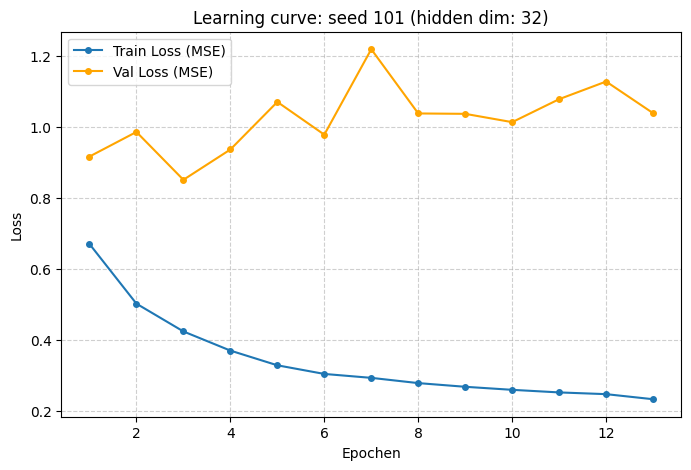

[I 2026-11-12 14:21:28,674] Trial 1 finished with value: 0.8508197728555195 and parameters: {'cut_height': 0.992, 'min_module_size': 20}. Best is trial 1 with value: 0.8508197728555195.


--> Result Seed 101: Best Epoch: 03 | Val Loss: 0.8508 | Test RMSE: 1.9234 | Test R²: 0.5815

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           3   0.85082   1.923409 0.581548  1.548215           0.790626            0.651234

--- Aggregated metrics (mean ± std) ---
Test RMSE: 1.9234 ± nan
Test R²:   0.5815 ± nan
Test Spearman coefficient: 0.6512 ± nan
Test Pearson coefficient: 0.7906 ± nan
Test mean absolute error: 1.5482 ± nan




[I 2026-11-12 14:21:30,361] Trial 2 pruned. 



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


... (4 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


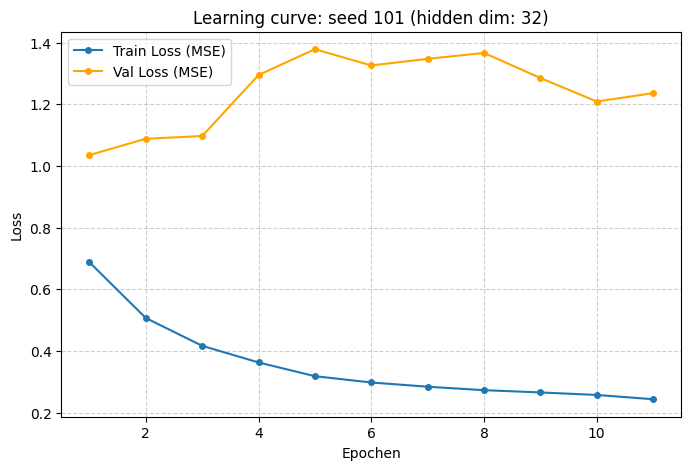

[I 2026-11-12 14:30:24,412] Trial 3 finished with value: 1.0351111634769816 and parameters: {'cut_height': 0.992, 'min_module_size': 30}. Best is trial 1 with value: 0.8508197728555195.


--> Result Seed 101: Best Epoch: 01 | Val Loss: 1.0351 | Test RMSE: 2.2128 | Test R²: 0.4461

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           1  1.035111   2.212837 0.446138  1.729236           0.730192             0.59442

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.2128 ± nan
Test R²:   0.4461 ± nan
Test Spearman coefficient: 0.5944 ± nan
Test Pearson coefficient: 0.7302 ± nan
Test mean absolute error: 1.7292 ± nan




[I 2026-11-12 14:30:26,009] Trial 4 pruned. 



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


... (4 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


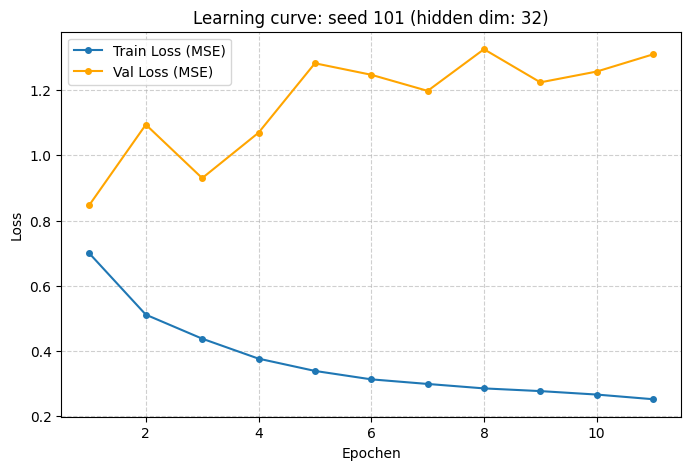

[I 2026-11-12 14:39:13,547] Trial 5 finished with value: 0.8480337905098934 and parameters: {'cut_height': 0.98, 'min_module_size': 30}. Best is trial 5 with value: 0.8480337905098934.


--> Result Seed 101: Best Epoch: 01 | Val Loss: 0.8480 | Test RMSE: 1.9855 | Test R²: 0.5541

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           1  0.848034    1.98555 0.554072  1.634565             0.7465            0.569769

--- Aggregated metrics (mean ± std) ---
Test RMSE: 1.9855 ± nan
Test R²:   0.5541 ± nan
Test Spearman coefficient: 0.5698 ± nan
Test Pearson coefficient: 0.7465 ± nan
Test mean absolute error: 1.6346 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


EarlyStopping counter: 4 out of 10


... (2 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


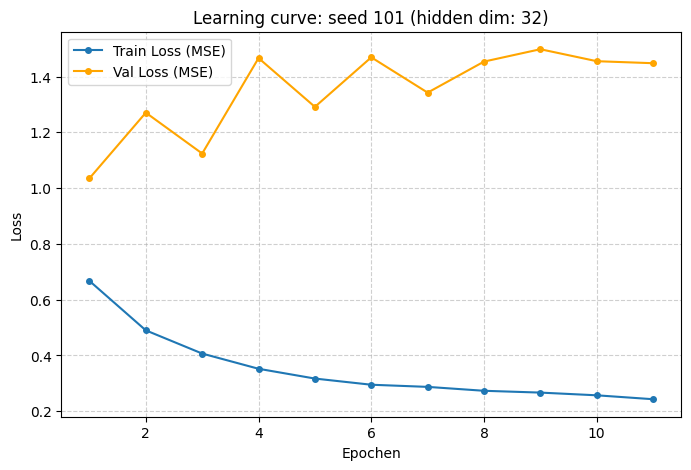

[I 2026-11-12 14:48:05,827] Trial 6 finished with value: 1.0351494662408753 and parameters: {'cut_height': 0.995, 'min_module_size': 10}. Best is trial 5 with value: 0.8480337905098934.


--> Result Seed 101: Best Epoch: 01 | Val Loss: 1.0351 | Test RMSE: 2.1436 | Test R²: 0.4803

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           1  1.035149     2.1436 0.480255  1.742516           0.705863            0.586004

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.1436 ± nan
Test R²:   0.4803 ± nan
Test Spearman coefficient: 0.5860 ± nan
Test Pearson coefficient: 0.7059 ± nan
Test mean absolute error: 1.7425 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


... (3 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


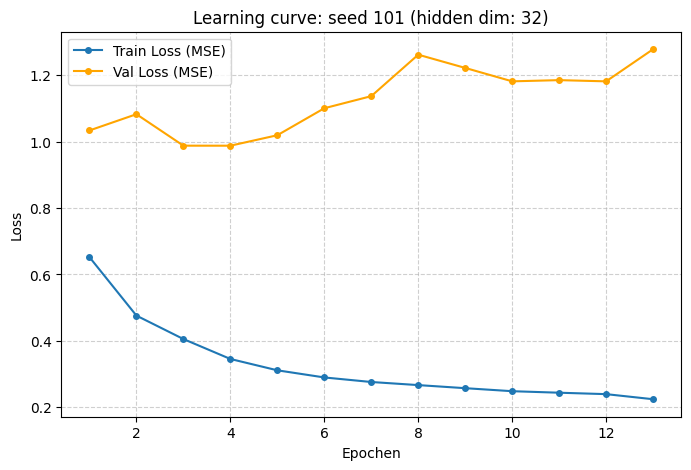

[I 2026-11-12 14:58:48,818] Trial 7 finished with value: 0.987611318334091 and parameters: {'cut_height': 0.999, 'min_module_size': 20}. Best is trial 5 with value: 0.8480337905098934.


--> Result Seed 101: Best Epoch: 04 | Val Loss: 0.9876 | Test RMSE: 2.1031 | Test R²: 0.4997

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           4  0.987611   2.103118   0.4997  1.663231           0.748257            0.633116

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.1031 ± nan
Test R²:   0.4997 ± nan
Test Spearman coefficient: 0.6331 ± nan
Test Pearson coefficient: 0.7483 ± nan
Test mean absolute error: 1.6632 ± nan




[I 2026-11-12 14:58:50,244] Trial 8 pruned. 



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


... (4 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


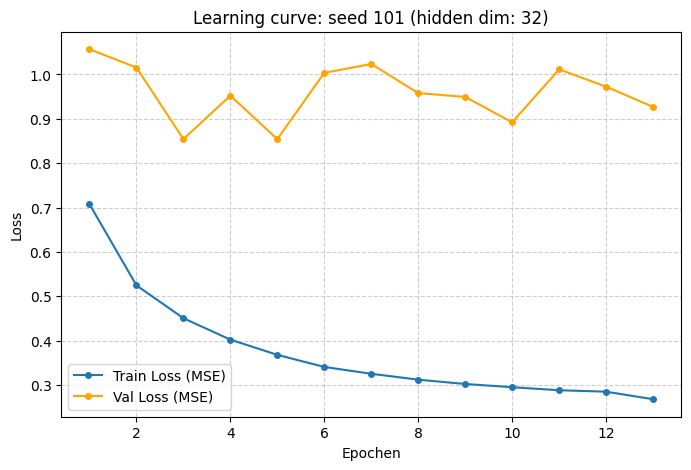

[I 2026-11-12 15:09:25,359] Trial 9 finished with value: 0.8542439484375355 and parameters: {'cut_height': 0.95, 'min_module_size': 10}. Best is trial 5 with value: 0.8480337905098934.


--> Result Seed 101: Best Epoch: 05 | Val Loss: 0.8542 | Test RMSE: 2.4536 | Test R²: 0.3191

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           5  0.854244   2.453586 0.319065  1.938979           0.576348            0.464528

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.4536 ± nan
Test R²:   0.3191 ± nan
Test Spearman coefficient: 0.4645 ± nan
Test Pearson coefficient: 0.5763 ± nan
Test mean absolute error: 1.9390 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


EarlyStopping counter: 4 out of 10


... (2 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


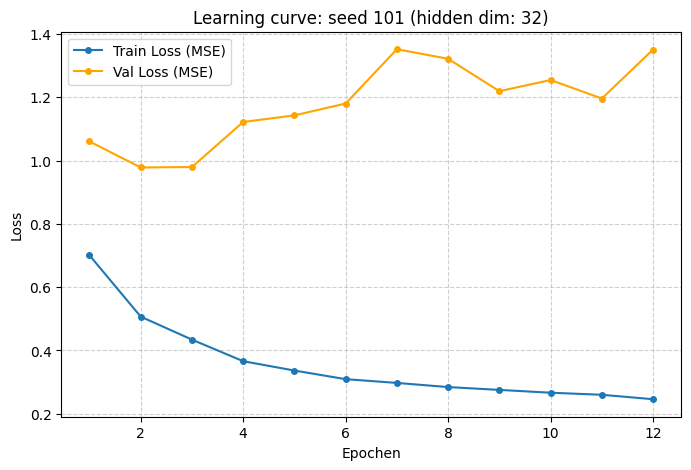

[I 2026-11-12 15:19:00,542] Trial 10 finished with value: 0.9782037251061069 and parameters: {'cut_height': 0.98, 'min_module_size': 30}. Best is trial 5 with value: 0.8480337905098934.


--> Result Seed 101: Best Epoch: 02 | Val Loss: 0.9782 | Test RMSE: 2.2056 | Test R²: 0.4497

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           2  0.978204   2.205614 0.449748  1.728579           0.685503            0.574721

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.2056 ± nan
Test R²:   0.4497 ± nan
Test Spearman coefficient: 0.5747 ± nan
Test Pearson coefficient: 0.6855 ± nan
Test mean absolute error: 1.7286 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


EarlyStopping counter: 4 out of 10


... (2 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


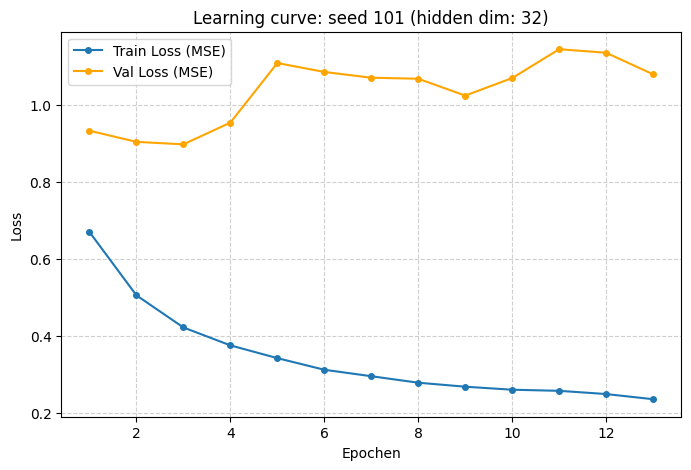

[I 2026-11-12 15:29:43,353] Trial 11 finished with value: 0.8975291599003719 and parameters: {'cut_height': 0.992, 'min_module_size': 20}. Best is trial 5 with value: 0.8480337905098934.


--> Result Seed 101: Best Epoch: 03 | Val Loss: 0.8975 | Test RMSE: 2.0639 | Test R²: 0.5182

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           3  0.897529   2.063944 0.518165  1.628429           0.789457             0.66505

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.0639 ± nan
Test R²:   0.5182 ± nan
Test Spearman coefficient: 0.6651 ± nan
Test Pearson coefficient: 0.7895 ± nan
Test mean absolute error: 1.6284 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


... (3 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


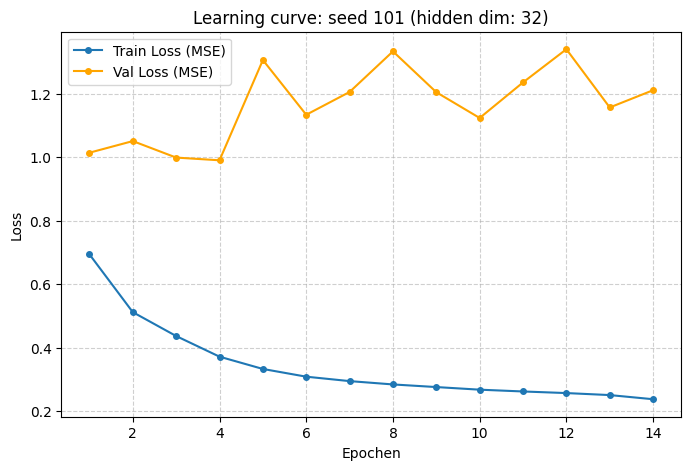

[I 2026-11-12 15:41:23,843] Trial 12 finished with value: 0.9902380291241014 and parameters: {'cut_height': 0.98, 'min_module_size': 20}. Best is trial 5 with value: 0.8480337905098934.


--> Result Seed 101: Best Epoch: 04 | Val Loss: 0.9902 | Test RMSE: 2.3634 | Test R²: 0.3682

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           4  0.990238   2.363443 0.368181  1.789112           0.671467             0.58775

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.3634 ± nan
Test R²:   0.3682 ± nan
Test Spearman coefficient: 0.5878 ± nan
Test Pearson coefficient: 0.6715 ± nan
Test mean absolute error: 1.7891 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


EarlyStopping counter: 4 out of 10


... (2 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


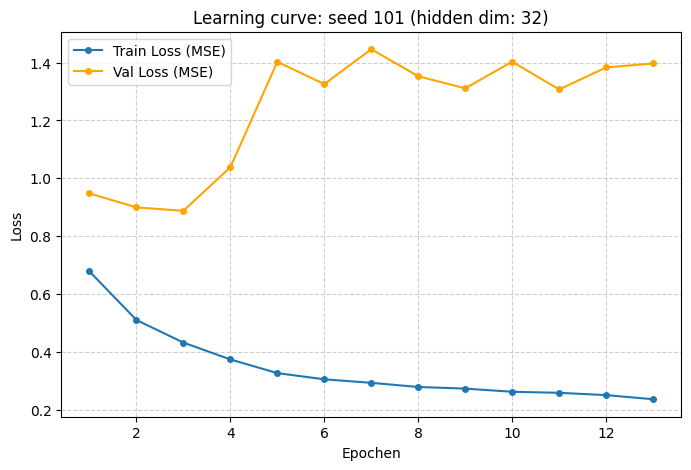

[I 2026-11-12 15:52:01,965] Trial 13 finished with value: 0.8876301237697927 and parameters: {'cut_height': 0.99, 'min_module_size': 30}. Best is trial 5 with value: 0.8480337905098934.


--> Result Seed 101: Best Epoch: 03 | Val Loss: 0.8876 | Test RMSE: 2.2526 | Test R²: 0.4261

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           3   0.88763   2.252558 0.426076  1.667342           0.699313            0.634727

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.2526 ± nan
Test R²:   0.4261 ± nan
Test Spearman coefficient: 0.6347 ± nan
Test Pearson coefficient: 0.6993 ± nan
Test mean absolute error: 1.6673 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


EarlyStopping counter: 4 out of 10


... (2 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


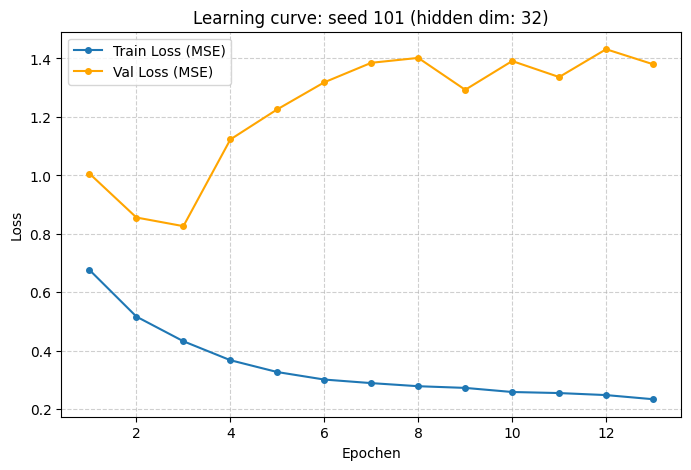

[I 2026-11-12 16:08:26,342] Trial 14 finished with value: 0.8265189964277431 and parameters: {'cut_height': 0.99, 'min_module_size': 20}. Best is trial 14 with value: 0.8265189964277431.


--> Result Seed 101: Best Epoch: 03 | Val Loss: 0.8265 | Test RMSE: 2.3438 | Test R²: 0.3786

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           3  0.826519   2.343811 0.378633   1.75832           0.709997            0.631798

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.3438 ± nan
Test R²:   0.3786 ± nan
Test Spearman coefficient: 0.6318 ± nan
Test Pearson coefficient: 0.7100 ± nan
Test mean absolute error: 1.7583 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


EarlyStopping counter: 4 out of 10


... (2 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


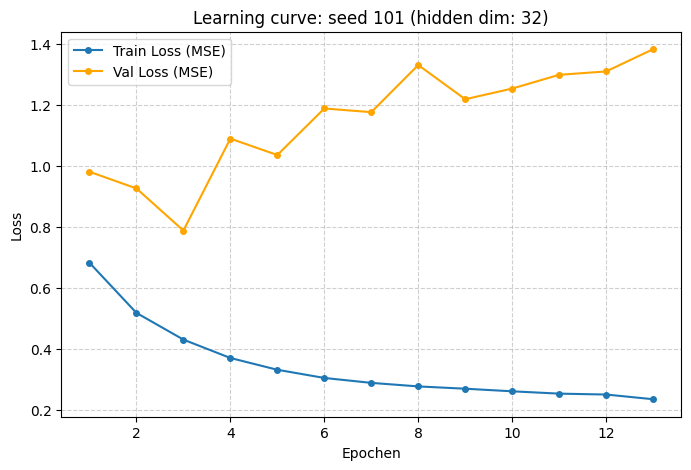

[I 2026-11-13 11:25:00,260] Trial 15 finished with value: 0.7891533202921507 and parameters: {'cut_height': 0.99, 'min_module_size': 20}. Best is trial 15 with value: 0.7891533202921507.


--> Result Seed 101: Best Epoch: 03 | Val Loss: 0.7892 | Test RMSE: 2.3236 | Test R²: 0.3893

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           3  0.789153   2.323577 0.389315  1.742618           0.716327            0.635697

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.3236 ± nan
Test R²:   0.3893 ± nan
Test Spearman coefficient: 0.6357 ± nan
Test Pearson coefficient: 0.7163 ± nan
Test mean absolute error: 1.7426 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


EarlyStopping counter: 4 out of 10


... (2 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


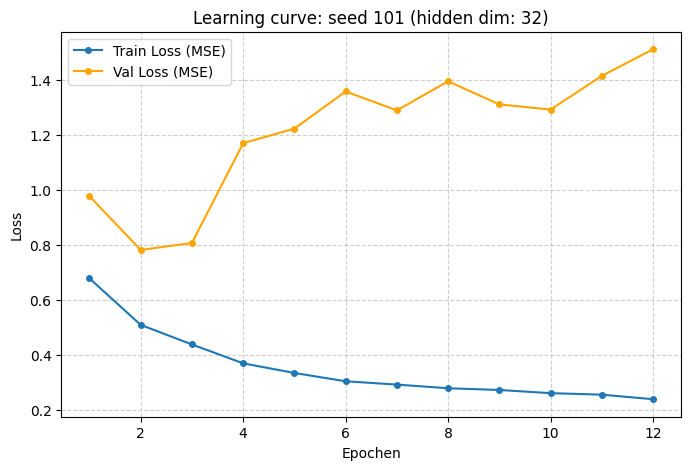

[I 2026-11-13 11:34:17,533] Trial 16 finished with value: 0.7827393601064039 and parameters: {'cut_height': 0.99, 'min_module_size': 20}. Best is trial 16 with value: 0.7827393601064039.


--> Result Seed 101: Best Epoch: 02 | Val Loss: 0.7827 | Test RMSE: 1.9987 | Test R²: 0.5482

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           2  0.782739   1.998684 0.548153  1.606045            0.78536            0.607463

--- Aggregated metrics (mean ± std) ---
Test RMSE: 1.9987 ± nan
Test R²:   0.5482 ± nan
Test Spearman coefficient: 0.6075 ± nan
Test Pearson coefficient: 0.7854 ± nan
Test mean absolute error: 1.6060 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


... (3 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


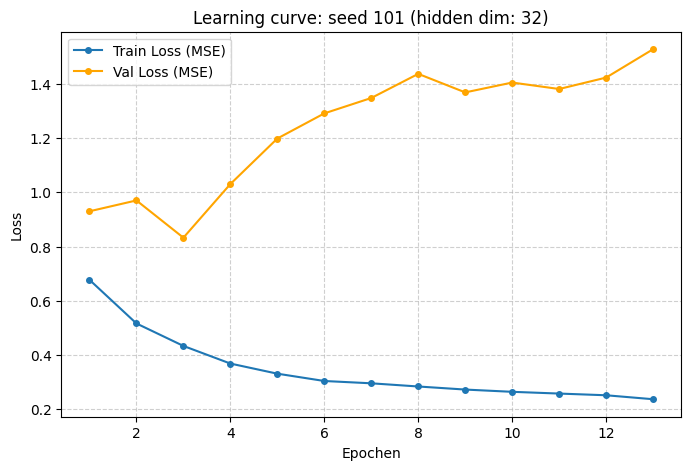

[I 2026-11-13 11:45:03,206] Trial 17 finished with value: 0.8326203731300037 and parameters: {'cut_height': 0.99, 'min_module_size': 20}. Best is trial 16 with value: 0.7827393601064039.


--> Result Seed 101: Best Epoch: 03 | Val Loss: 0.8326 | Test RMSE: 2.3626 | Test R²: 0.3686

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           3   0.83262   2.362634 0.368613  1.767774           0.724658            0.639422

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.3626 ± nan
Test R²:   0.3686 ± nan
Test Spearman coefficient: 0.6394 ± nan
Test Pearson coefficient: 0.7247 ± nan
Test mean absolute error: 1.7678 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


EarlyStopping counter: 4 out of 10


... (2 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


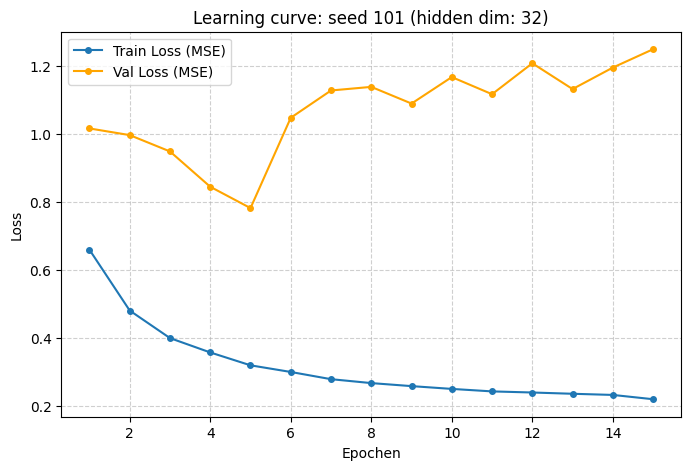

[I 2026-11-13 11:57:24,913] Trial 18 finished with value: 0.7819085524794578 and parameters: {'cut_height': 0.995, 'min_module_size': 20}. Best is trial 18 with value: 0.7819085524794578.


--> Result Seed 101: Best Epoch: 05 | Val Loss: 0.7819 | Test RMSE: 2.1415 | Test R²: 0.4813

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           5  0.781909   2.141514 0.481266  1.667089           0.709509            0.638415

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.1415 ± nan
Test R²:   0.4813 ± nan
Test Spearman coefficient: 0.6384 ± nan
Test Pearson coefficient: 0.7095 ± nan
Test mean absolute error: 1.6671 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


... (3 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


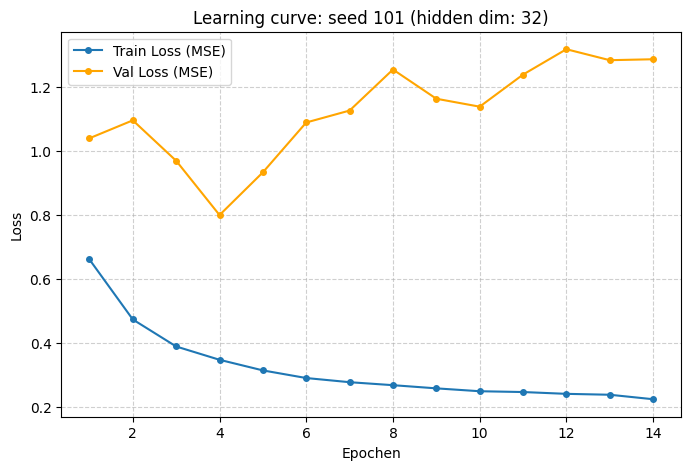

[I 2026-11-13 12:08:31,023] Trial 19 finished with value: 0.7986274121928367 and parameters: {'cut_height': 0.995, 'min_module_size': 20}. Best is trial 18 with value: 0.7819085524794578.


--> Result Seed 101: Best Epoch: 04 | Val Loss: 0.7986 | Test RMSE: 2.1207 | Test R²: 0.4913

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           4  0.798627   2.120656 0.491322  1.646755           0.723286            0.610932

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.1207 ± nan
Test R²:   0.4913 ± nan
Test Spearman coefficient: 0.6109 ± nan
Test Pearson coefficient: 0.7233 ± nan
Test mean absolute error: 1.6468 ± nan




[I 2026-11-13 12:08:32,640] Trial 20 pruned. 



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


... (4 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


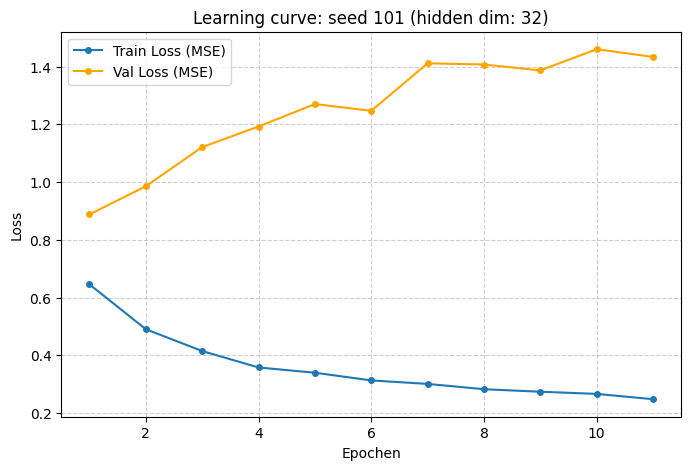

[I 2026-11-13 12:17:25,174] Trial 21 finished with value: 0.8881778416695859 and parameters: {'cut_height': 0.99, 'min_module_size': 10}. Best is trial 18 with value: 0.7819085524794578.


--> Result Seed 101: Best Epoch: 01 | Val Loss: 0.8882 | Test RMSE: 2.0363 | Test R²: 0.5310

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           1  0.888178   2.036274 0.530997   1.63096           0.757173            0.611835

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.0363 ± nan
Test R²:   0.5310 ± nan
Test Spearman coefficient: 0.6118 ± nan
Test Pearson coefficient: 0.7572 ± nan
Test mean absolute error: 1.6310 ± nan




[I 2026-11-13 12:17:26,636] Trial 22 pruned. 



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


... (4 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


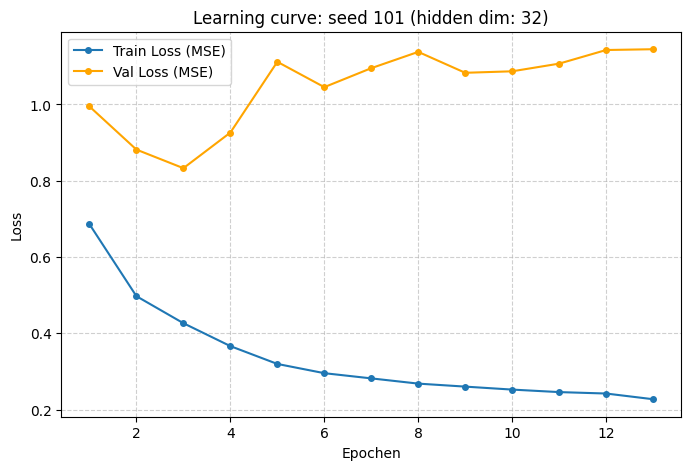

[I 2026-11-13 12:27:49,495] Trial 23 finished with value: 0.8328659227331655 and parameters: {'cut_height': 0.995, 'min_module_size': 30}. Best is trial 18 with value: 0.7819085524794578.


--> Result Seed 101: Best Epoch: 03 | Val Loss: 0.8329 | Test RMSE: 2.1013 | Test R²: 0.5006

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           3  0.832866   2.101321 0.500555  1.647837           0.768518            0.660186

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.1013 ± nan
Test R²:   0.5006 ± nan
Test Spearman coefficient: 0.6602 ± nan
Test Pearson coefficient: 0.7685 ± nan
Test mean absolute error: 1.6478 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


... (3 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


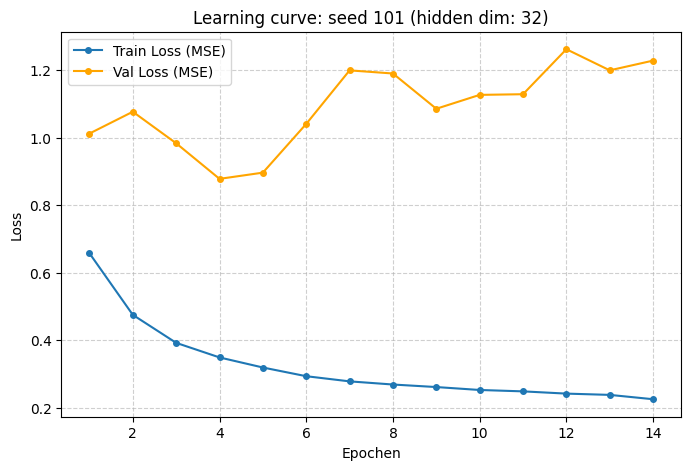

[I 2026-11-13 12:37:27,907] Trial 24 finished with value: 0.877829965699503 and parameters: {'cut_height': 0.995, 'min_module_size': 20}. Best is trial 18 with value: 0.7819085524794578.


--> Result Seed 101: Best Epoch: 04 | Val Loss: 0.8778 | Test RMSE: 2.1201 | Test R²: 0.4916

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           4   0.87783    2.12014 0.491569  1.663092           0.708997            0.608181

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.1201 ± nan
Test R²:   0.4916 ± nan
Test Spearman coefficient: 0.6082 ± nan
Test Pearson coefficient: 0.7090 ± nan
Test mean absolute error: 1.6631 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


EarlyStopping counter: 4 out of 10


... (2 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


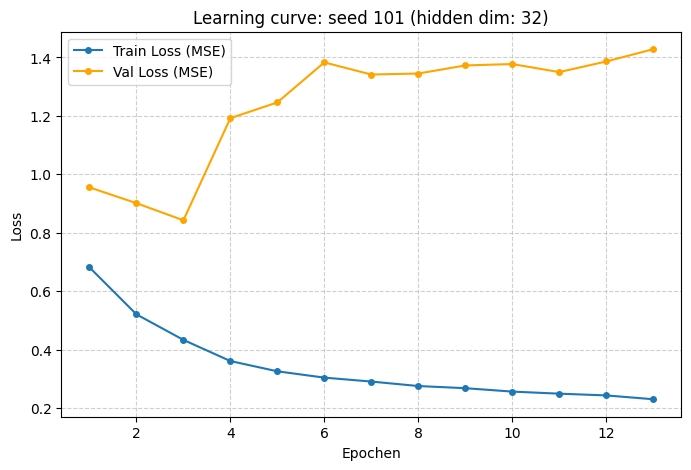

[I 2026-11-13 12:46:10,930] Trial 25 finished with value: 0.8426806974462888 and parameters: {'cut_height': 0.99, 'min_module_size': 20}. Best is trial 18 with value: 0.7819085524794578.


--> Result Seed 101: Best Epoch: 03 | Val Loss: 0.8427 | Test RMSE: 2.2132 | Test R²: 0.4459

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           3  0.842681    2.21322 0.445946  1.690426           0.729522            0.645938

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.2132 ± nan
Test R²:   0.4459 ± nan
Test Spearman coefficient: 0.6459 ± nan
Test Pearson coefficient: 0.7295 ± nan
Test mean absolute error: 1.6904 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


EarlyStopping counter: 4 out of 10


... (2 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


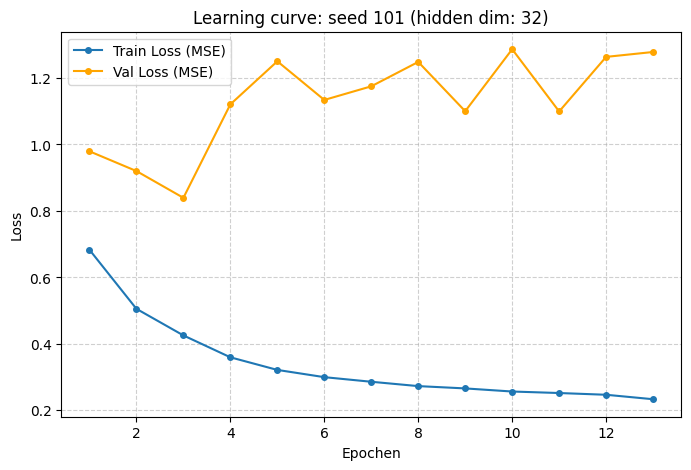

[I 2026-11-13 12:54:37,619] Trial 26 finished with value: 0.839463922984476 and parameters: {'cut_height': 0.99, 'min_module_size': 20}. Best is trial 18 with value: 0.7819085524794578.


--> Result Seed 101: Best Epoch: 03 | Val Loss: 0.8395 | Test RMSE: 2.3169 | Test R²: 0.3928

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           3  0.839464    2.31688 0.392831  1.741291           0.719737            0.630063

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.3169 ± nan
Test R²:   0.3928 ± nan
Test Spearman coefficient: 0.6301 ± nan
Test Pearson coefficient: 0.7197 ± nan
Test mean absolute error: 1.7413 ± nan



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


... (3 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


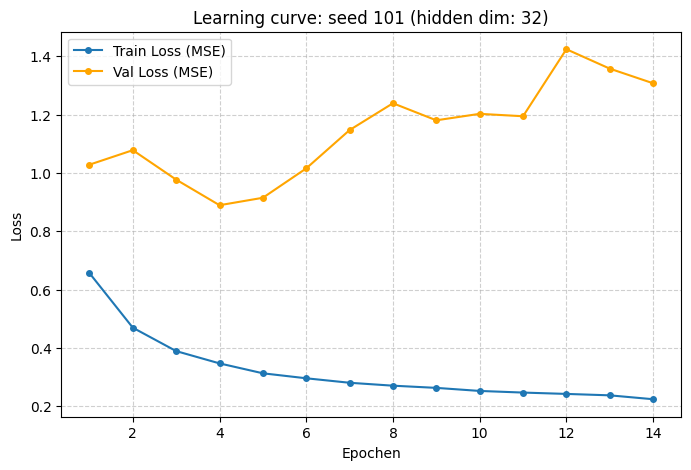

[I 2026-11-13 13:04:28,985] Trial 27 finished with value: 0.8893070711105207 and parameters: {'cut_height': 0.995, 'min_module_size': 20}. Best is trial 18 with value: 0.7819085524794578.


--> Result Seed 101: Best Epoch: 04 | Val Loss: 0.8893 | Test RMSE: 2.1776 | Test R²: 0.4637

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           4  0.889307   2.177552  0.46366  1.688138           0.711325            0.610304

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.1776 ± nan
Test R²:   0.4637 ± nan
Test Spearman coefficient: 0.6103 ± nan
Test Pearson coefficient: 0.7113 ± nan
Test mean absolute error: 1.6881 ± nan




[I 2026-11-13 13:04:30,328] Trial 28 pruned. 



Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


... (4 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


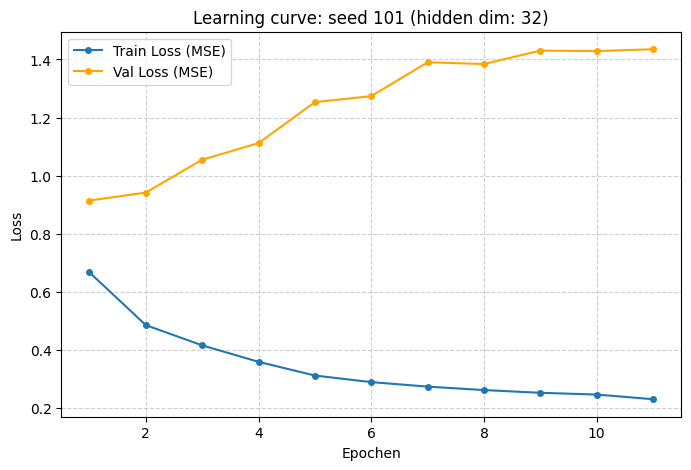

[I 2026-11-13 13:13:11,614] Trial 29 finished with value: 0.9138114017470306 and parameters: {'cut_height': 0.999, 'min_module_size': 30}. Best is trial 18 with value: 0.7819085524794578.


--> Result Seed 101: Best Epoch: 01 | Val Loss: 0.9138 | Test RMSE: 2.1393 | Test R²: 0.4823

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           1  0.913811   2.139277 0.482349  1.664663           0.717706            0.632653

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.1393 ± nan
Test R²:   0.4823 ± nan
Test Spearman coefficient: 0.6327 ± nan
Test Pearson coefficient: 0.7177 ± nan
Test mean absolute error: 1.6647 ± nan


Beste Parameter: {'cut_height': 0.995, 'min_module_size': 20}
Bester mittlerer Val-MSE: 0.7819085524794578
Anzahl Module: 3
Modulgrößen: [21, 124, 128]


In [80]:
import optuna

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)

print("Beste Parameter:", study.best_params)
print("Bester mittlerer Val-MSE:", study.best_value)
print("Anzahl Module:", study.best_trial.user_attrs["n_modules"])
print("Modulgrößen:", study.best_trial.user_attrs["module_sizes"])

In [81]:
print("Beste Parameter:", study.best_params)
print("Bester mittlerer Val-MSE:", study.best_value)
print("Anzahl Module:", study.best_trial.user_attrs["n_modules"])
print("Modulgrößen:", study.best_trial.user_attrs["module_sizes"])

Beste Parameter: {'cut_height': 0.995, 'min_module_size': 20}
Bester mittlerer Val-MSE: 0.7819085524794578
Anzahl Module: 3
Modulgrößen: [21, 124, 128]


#### Visualization of gene clusters

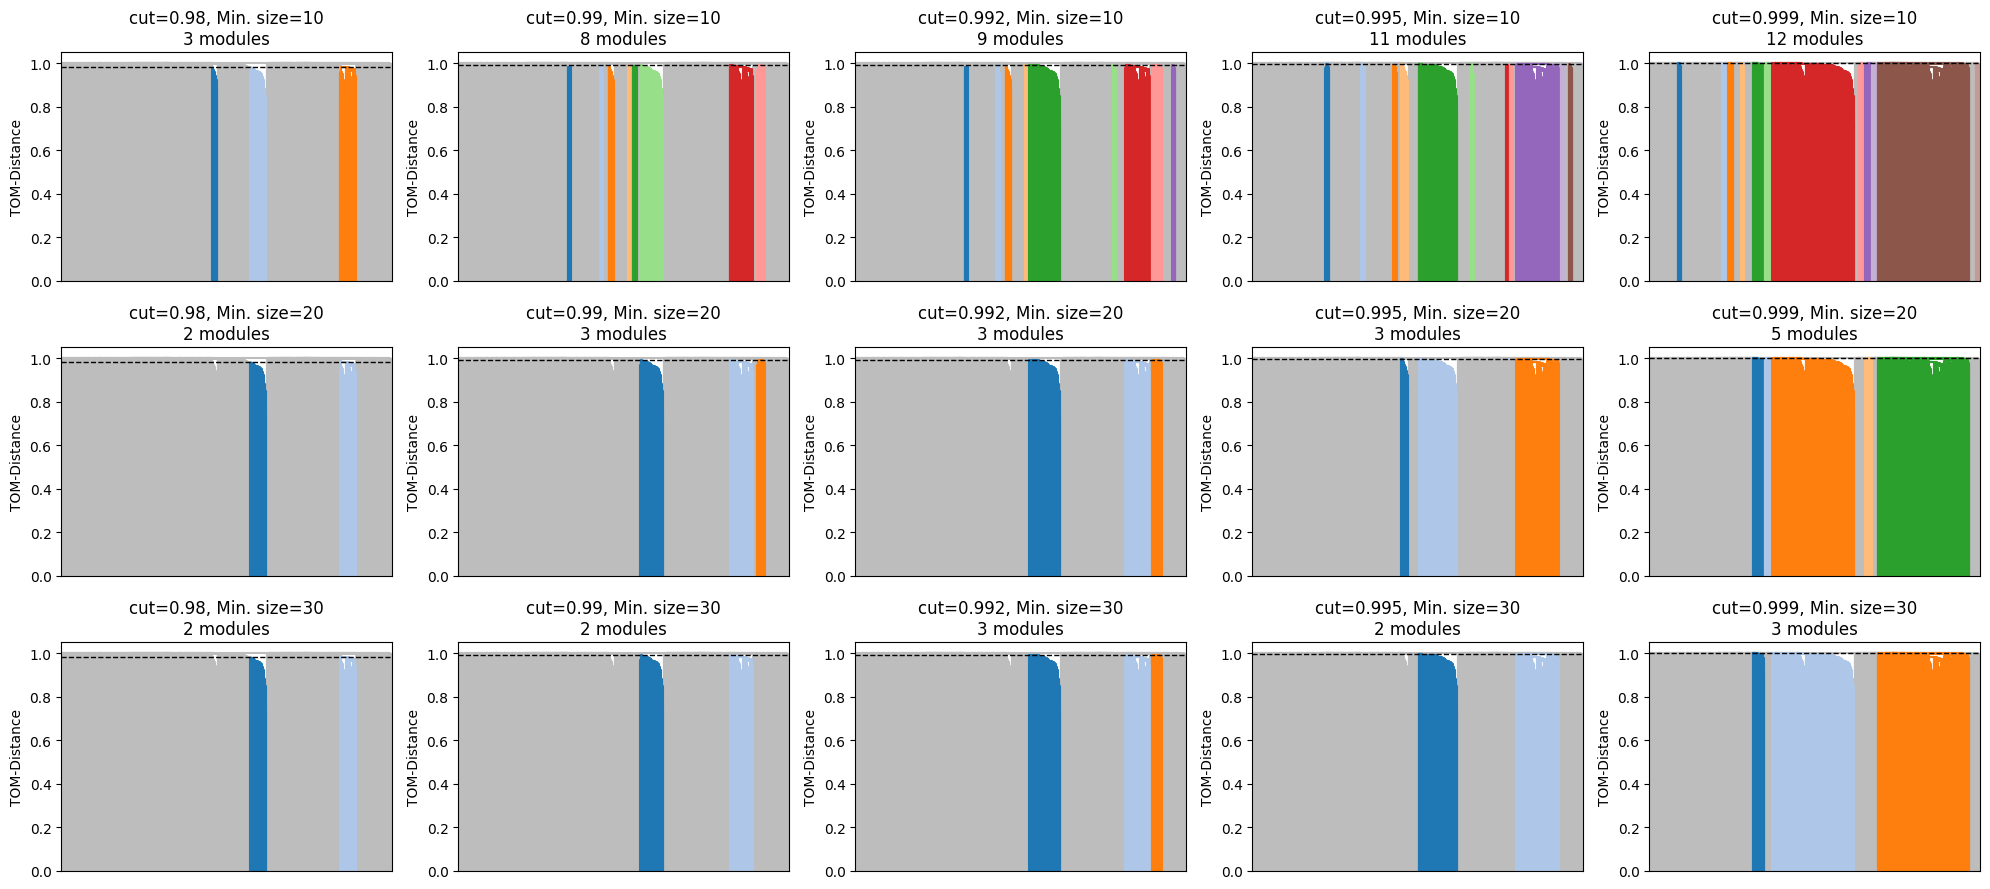

In [83]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from scipy.cluster.hierarchy import dendrogram, fcluster

cut_heights = [0.98, 0.99, 0.992, 0.995, 0.999]
min_module_sizes = [10, 20, 30]
n_genes = Z.shape[0] + 1
node_leaves = {i: [i] for i in range(n_genes)}

for i, (left, right, _, _) in enumerate(Z):
    node_id = n_genes + i
    node_leaves[node_id] = (
        node_leaves[int(left)] + node_leaves[int(right)]
    )

fig, axes = plt.subplots(
    len(min_module_sizes),
    len(cut_heights),
    figsize=(4 * len(cut_heights), 3 * len(min_module_sizes)),
    squeeze=False,
)

for row, min_size in enumerate(min_module_sizes):
    for col, cut_height in enumerate(cut_heights):
        ax = axes[row, col]

        labels = fcluster(Z, t=cut_height, criterion="distance")
        cluster_ids, sizes = np.unique(labels, return_counts=True)
        cluster_sizes = dict(zip(cluster_ids, sizes))
        kept = {
            cluster_id
            for cluster_id, size in cluster_sizes.items()
            if size >= min_size
        }

        # Dieselben Cluster behalten bei gegebener cut_height dieselbe Farbe.
        cmap = plt.get_cmap("tab20")
        cluster_colors = {
            cluster_id: to_hex(cmap(i % 20))
            for i, cluster_id in enumerate(sorted(kept))
        }

        link_colors = {}
        for node_id, leaves in node_leaves.items():
            if node_id < n_genes:
                continue  # Einzelne Gene sind Blattknoten.

            node_clusters = np.unique(labels[leaves])
            if len(node_clusters) == 1 and node_clusters[0] in kept:
                link_colors[node_id] = cluster_colors[node_clusters[0]]
            else:
                link_colors[node_id] = "#BDBDBD"

        dendrogram(
            Z,
            ax=ax,
            no_labels=True,
            color_threshold=0,  # Farben kommen aus link_color_func
            link_color_func=lambda node_id: link_colors.get(
                node_id, "#BDBDBD"
            ),
        )

        ax.axhline(cut_height, color="black", linestyle="--", linewidth=1)
        ax.set_title(
            f"cut={cut_height}, Min. size={min_size}\n"
            f"{len(kept)} modules"
        )
        ax.set_ylabel("TOM-Distance")

plt.tight_layout()
plt.show()

Bei vielen Genen kann das vollständige Dendrogramm dicht wirken. Dann kannst du die Anzahl der dargestellten Äste reduzieren, etwa mit truncate_mode="lastp" und p=50 im dendrogram-Aufruf. Das macht die Darstellung lesbarer, zeigt aber nicht mehr jedes einzelne Gen.

## Configuration and training for tabular fingerprints (drugs)

First creation of drug tokens

In [15]:
'''import numpy as np
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import pdist

# Select chemical columns
chem_cols = pharmacophores + mfp_cols

# Extract unique drug feature matrix
unique_drugs_df = df.drop_duplicates(subset=['DRUG_ID'])[chem_cols]
chem_values = unique_drugs_df.values.astype(np.float64)  # shape: (n_drugs, 1032)

# Compute Pearson correlation with variance check
# Identify constant columns (zero variance)
std_devs = np.std(chem_values, axis=0)
valid_mask = std_devs > 1e-8

# Compute correlation matrix
chem_corr = np.zeros((len(chem_cols), len(chem_cols)), dtype=np.float64)

# Correlate non-constant features
chem_corr_valid = np.corrcoef(chem_values[:, valid_mask].T)

# Place valid correlations into full matrix
valid_indices = np.where(valid_mask)[0]
for i_idx, i in enumerate(valid_indices):
    for j_idx, j in enumerate(valid_indices):
        chem_corr[i, j] = chem_corr_valid[i_idx, j_idx]

# Convert correlation to distance: dist = 1 - r
dist_matrix_chem = 1.0 - chem_corr

# Handle any remaining NaN/Inf values by setting distance to 1.0 (uncorrelated)
dist_matrix_chem = np.nan_to_num(dist_matrix_chem, nan=1.0, posinf=1.0, neginf=1.0)
dist_matrix_chem = np.clip(dist_matrix_chem, 0.0, 2.0)
np.fill_diagonal(dist_matrix_chem, 0.0)

# Hierarchical clustering on condensed distance matrix
condensed_dist = pdist(dist_matrix_chem)
linkage_chem = linkage(condensed_dist, method='ward')

# Extract cluster labels for X tokens
num_drug_tokens = 32
chem_cluster_labels = fcluster(linkage_chem, t=num_drug_tokens, criterion='maxclust') - 1

# Form index arrays for each token
chem_token_indices = [
    np.where(chem_cluster_labels == i)[0] for i in range(num_drug_tokens)
]

for i, idx in enumerate(chem_token_indices):
    print(f"Drug Token {i}: {len(idx)} features assigned")'''

'import numpy as np\nfrom scipy.cluster.hierarchy import fcluster, linkage\nfrom scipy.spatial.distance import pdist\n\n# Select chemical columns\nchem_cols = pharmacophores + mfp_cols\n\n# Extract unique drug feature matrix\nunique_drugs_df = df.drop_duplicates(subset=[\'DRUG_ID\'])[chem_cols]\nchem_values = unique_drugs_df.values.astype(np.float64)  # shape: (n_drugs, 1032)\n\n# Compute Pearson correlation with variance check\n# Identify constant columns (zero variance)\nstd_devs = np.std(chem_values, axis=0)\nvalid_mask = std_devs > 1e-8\n\n# Compute correlation matrix\nchem_corr = np.zeros((len(chem_cols), len(chem_cols)), dtype=np.float64)\n\n# Correlate non-constant features\nchem_corr_valid = np.corrcoef(chem_values[:, valid_mask].T)\n\n# Place valid correlations into full matrix\nvalid_indices = np.where(valid_mask)[0]\nfor i_idx, i in enumerate(valid_indices):\n    for j_idx, j in enumerate(valid_indices):\n        chem_corr[i, j] = chem_corr_valid[i_idx, j_idx]\n\n# Convert c

In [ ]:
'''from sklearn.preprocessing import MinMaxScaler
target = 'LN_IC50'
pharmacophores = ['Donor', 'Acceptor', 'Aromatic', 'Hydrophobe', 'LumpedHydrophobe',
                   'PosIonizable', 'NegIonizable', 'ZnBinder']
mfp_cols = [col for col in df.columns if col.startswith('Bit_')]

X_genomic_raw = df.filter(regex=r'.* \(.*\)').values.astype('float32')
X_chem_raw = df[pharmacophores + mfp_cols]
y_raw = df[target].values.astype('float32')
drug_groups = df['DRUG_ID'].values

seeds = [42, 101, 1337, 9999]
#seeds = [101]
hidden_dim = 64
dropout = 0.1
lr = 2e-4
weight_decay = 1e-3
epochs = 25
patience = 5
batch_size = 512

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Used device:", device)

# ==========================================
# Run data splits and scaling ONCE
# ==========================================
print("\nPrepare datasets and GPU tensors...")
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.10, random_state=18092026)
idx_train_val, idx_test = next(gss_test.split(X_genomic_raw, y_raw, groups=drug_groups))

groups_train_val = drug_groups[idx_train_val]
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.11, random_state=18092026)
idx_tr_rel, idx_val_rel = next(
    gss_val.split(X_genomic_raw[idx_train_val], y_raw[idx_train_val], groups=groups_train_val)
)
idx_train = idx_train_val[idx_tr_rel]
idx_val = idx_train_val[idx_val_rel]

# Feature-Skalierung
preprocessor = ColumnTransformer(
    transformers=[
        ('pharmacophore', StandardScaler(), pharmacophores),
        ('mfp', 'passthrough', mfp_cols)
    ],
    remainder='drop'
)
gene_scaler = StandardScaler()

X_gen_train = gene_scaler.fit_transform(X_genomic_raw[idx_train])
X_chem_train = preprocessor.fit_transform(X_chem_raw.iloc[idx_train])

X_gen_val = gene_scaler.transform(X_genomic_raw[idx_val])
X_chem_val = preprocessor.transform(X_chem_raw.iloc[idx_val])

X_gen_test = gene_scaler.transform(X_genomic_raw[idx_test])
X_chem_test = preprocessor.transform(X_chem_raw.iloc[idx_test])

# Target scaling to [0.05, 0.95] for a stable sigmoid output
y_scaler = MinMaxScaler(feature_range=(0.05, 0.95))
y_train_scaled = y_scaler.fit_transform(y_raw[idx_train].reshape(-1, 1)).flatten().astype('float32')
y_val_scaled   = y_scaler.transform(y_raw[idx_val].reshape(-1, 1)).flatten().astype('float32')
y_test_orig    = y_raw[idx_test]

# Load data sets completely into VRAM (no more CPU transfers in the loop!)
t_X_gen_train  = torch.as_tensor(X_gen_train, dtype=torch.float32, device=device)
t_X_chem_train = torch.as_tensor(X_chem_train, dtype=torch.float32, device=device)
t_y_train      = torch.as_tensor(y_train_scaled, dtype=torch.float32, device=device)

t_X_gen_val    = torch.as_tensor(X_gen_val, dtype=torch.float32, device=device)
t_X_chem_val   = torch.as_tensor(X_chem_val, dtype=torch.float32, device=device)
t_y_val        = torch.as_tensor(y_val_scaled, dtype=torch.float32, device=device)

t_X_gen_test   = torch.as_tensor(X_gen_test, dtype=torch.float32, device=device)
t_X_chem_test  = torch.as_tensor(X_chem_test, dtype=torch.float32, device=device)

n_train = t_X_gen_train.size(0)
n_val   = t_X_gen_val.size(0)
n_test  = t_X_gen_test.size(0)
print(f"Daten im GPU-RAM: Train={n_train}, Val={n_val}, Test={n_test}")

# ==========================================
# Seed Evaluation
# ==========================================
seed_results = []
scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

for run_idx, seed in enumerate(seeds):
    print(f"\n==========================================")
    print(f"Seed {run_idx + 1}/{len(seeds)} (Seed-value: {seed})")
    print(f"==========================================")

    set_seed(seed)

    model = GroundedCrossAttentionModel(
        gene_token_indices=gene_token_indices,
        chem_token_indices=chem_token_indices,
        hidden_dim=hidden_dim,
        num_heads=4,
        dropout=dropout
    ).to(device)

    criterion = nn.MSELoss()
    #criterion = weighted_mse_loss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=patience)

    best_val_loss = float("inf")
    best_epoch = -1
    model_checkpoint_path = f"best_model_seed_{seed}.pt"

    for epoch in range(epochs):
        model.train()
        permutation = torch.randperm(n_train, device=device)
        train_loss = 0.0

        for i in range(0, n_train, batch_size):
            idx_batch = permutation[i:i + batch_size]
            b_genes = t_X_gen_train[idx_batch]
            b_chem  = t_X_chem_train[idx_batch]
            b_y     = t_y_train[idx_batch]

            optimizer.zero_grad(set_to_none=True)

            # Mixed Precision Forward Pass
            with torch.amp.autocast("cuda"):
                preds = model(b_genes, b_chem)
                loss = weighted_mse_loss(preds, b_y)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item() * b_genes.size(0)

        # Fast Validation on the GPU
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for i in range(0, n_val, batch_size):
                b_genes = t_X_gen_val[i:i + batch_size]
                b_chem  = t_X_chem_val[i:i + batch_size]
                b_y     = t_y_val[i:i + batch_size]

                with torch.amp.autocast(device_type="cuda"):
                    preds = model(b_genes, b_chem)
                    loss = weighted_mse_loss(preds, b_y)
                val_loss += loss.item() * b_genes.size(0)

        mean_val_loss = val_loss / n_val
        scheduler.step(mean_val_loss)

        if mean_val_loss < best_val_loss:
            best_val_loss = mean_val_loss
            best_epoch = epoch + 1
            torch.save(model.state_dict(), model_checkpoint_path)

    # Test Evaluation (with original scale for metrics)
    model.load_state_dict(torch.load(model_checkpoint_path, weights_only=True))
    model.eval()

    test_preds_list = []
    with torch.no_grad():
        for i in range(0, n_test, batch_size):
            b_genes = t_X_gen_test[i:i + batch_size]
            b_chem  = t_X_chem_test[i:i + batch_size]
            with torch.amp.autocast(device_type="cuda"):
                preds = model(b_genes, b_chem, save_attention=(i==0))
            test_preds_list.append(preds.cpu())

    # Merging and rescaling scaled predictions
    test_preds_scaled = torch.cat(test_preds_list).numpy()
    test_preds_orig = y_scaler.inverse_transform(test_preds_scaled.reshape(-1, 1)).flatten()

    test_rmse = root_mean_squared_error(y_test_orig, test_preds_orig)
    test_r2 = r2_score(y_test_orig, test_preds_orig)
    test_mae = mean_absolute_error(y_test_orig, test_preds_orig)
    test_pearson_corr, p_value_pearson = pearsonr(y_test_orig, test_preds_orig)
    test_spearman_corr, p_value_spearman = spearmanr(y_test_orig, test_preds_orig)
    #test_c_index = concordance_index(y_test_orig, test_preds_orig)

    print(f"--> Result Seed {seed}: Best Epoch: {best_epoch:02d} | Val Loss: {best_val_loss:.4f} | Test RMSE: {test_rmse:.4f} | Test R²: {test_r2:.4f}")

    seed_results.append({
        "seed": seed,
        "best_epoch": best_epoch,
        "val_loss": best_val_loss,
        "test_rmse": test_rmse,
        "test_r2": test_r2,
        "test_mae": test_mae,
        "test_pearson_corr": test_pearson_corr,
        "test_spearman_corr": test_spearman_corr#,
        #"test_c_index": test_c_index
    })

df_results = pd.DataFrame(seed_results)
print("\n" + "="*50)
print("Analysis of all seeds")
print("="*50)
print(df_results.to_string(index=False))
print("\n--- Aggregated metrics (mean ± std) ---")
print(f"Test RMSE: {df_results['test_rmse'].mean():.4f} ± {df_results['test_rmse'].std():.4f}")
print(f"Test R²:   {df_results['test_r2'].mean():.4f} ± {df_results['test_r2'].std():.4f}")
# Spearman does not measure absolute accuracy, but rather how well the order of the predictions matches reality.
# Spearman penalizes it somewhat more severely when an active ingredient that should
# actually be in first place slips to the very bottom of the list (e.g., 100th place) than the C-index would.
print(f"Test Spearman coefficient: {df_results['test_spearman_corr'].mean():.4f} ± {df_results['test_spearman_corr'].std():.4f}")
# Pearson correlation measures the linear relationship between your predictions and the true values (from -1 to +1).
print(f"Test Pearson coefficient: {df_results['test_pearson_corr'].mean():.4f} ± {df_results['test_pearson_corr'].std():.4f}")
# CI indicates the probability that, given two random samples, the model will correctly predict which of the two reacts more sensitively.
# Specifically, a C-index of 0.70 means this: If I select any two drug-cell line
# pairs from the test set, my model correctly predicts 70% of the time which of the two pairs has the lower Z-score.
# good to understand for biologists or doctors
#print(f"Concordance index: {df_results['test_c_index'].mean():.4f} ± {df_results['test_c_index'].std():.4f}")
# more robust than RMSE
print(f"Test mean absolute error: {df_results['test_mae'].mean():.4f} ± {df_results['test_mae'].std():.4f}")
print("\n" + "="*50 + "\n")
'''

<>:7: SyntaxWarning: invalid escape sequence '\('
<>:7: SyntaxWarning: invalid escape sequence '\('
/var/folders/vr/kvp0z9ld38j_hy0jr6hvmlj40000gn/T/ipykernel_63238/485416079.py:7: SyntaxWarning: invalid escape sequence '\('
  X_genomic_raw = df.filter(regex=r'.* \(.*\)').values.astype('float32')


'from sklearn.preprocessing import MinMaxScaler\ntarget = \'LN_IC50\'\npharmacophores = [\'Donor\', \'Acceptor\', \'Aromatic\', \'Hydrophobe\', \'LumpedHydrophobe\',\n                   \'PosIonizable\', \'NegIonizable\', \'ZnBinder\']\nmfp_cols = [col for col in df.columns if col.startswith(\'Bit_\')]\n\nX_genomic_raw = df.filter(regex=r\'.* \\(.*\\)\').values.astype(\'float32\')\nX_chem_raw = df[pharmacophores + mfp_cols]\ny_raw = df[target].values.astype(\'float32\')\ndrug_groups = df[\'DRUG_ID\'].values\n\nseeds = [42, 101, 1337, 9999]\n#seeds = [101]\nhidden_dim = 64\ndropout = 0.1\nlr = 2e-4\nweight_decay = 1e-3\nepochs = 25\npatience = 5\nbatch_size = 512\n\ndevice = torch.device("cuda" if torch.cuda.is_available() else "cpu")\nprint("Used device:", device)\n\n# ==========================================\n# Run data splits and scaling ONCE\n# ==========================================\nprint("\nPrepare datasets and GPU tensors...")\ngss_test = GroupShuffleSplit(n_splits=1, test_

## Configuration for graph representations (drugs)

### Parameters and data

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.model_selection import GroupShuffleSplit, StratifiedKFold
from torch_geometric.loader import DataLoader
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import importlib
import gnn_models_utils

target = 'LN_IC50'
smiles_raw = df['SMILES'].values
X_genomic_raw = df.filter(regex=r'.* \(.*\)').values.astype('float32')
y_raw = df[target].values.astype('float32')
drug_groups = df['DRUG_ID'].values

'''
# ==========================================
# TEMPORARY OUTLIER REMOVAL
# ==========================================
valid_mask = (y_raw >= -5.5) & (y_raw <= 7.5)
y_raw = y_raw[valid_mask]
X_genomic_raw = X_genomic_raw[valid_mask]
smiles_raw = smiles_raw[valid_mask]
drug_groups = drug_groups[valid_mask]
outliers_removed = (~valid_mask).sum()
print(f"Es wurden {outliers_removed} Ausreißer gelöscht.")
'''

'''print("Create 20% Subset for fast test-training...")
gss_subset = GroupShuffleSplit(n_splits=1, train_size=0.20, random_state=1337)
idx_subset, _ = next(gss_subset.split(X_genomic_raw, y_raw, groups=drug_groups))
smiles_raw = smiles_raw[idx_subset]
X_genomic_raw = X_genomic_raw[idx_subset]
y_raw = y_raw[idx_subset]
drug_groups = drug_groups[idx_subset]'''

#seeds = [42, 101, 1337, 9999]
seeds = [101]
hidden_dim = 32
dropout = 0.4
lr = 0.0005313322168980652
weight_decay = 1e-2
epochs = 30
patience = 8
batch_size = 256
gnn_type="GCN"  # Options: "GCN", "GAT", "GIN"
freeze_bool = True  # Whether to freeze the MolCLR backbone during training
#hidden_dim': 128, 'lr': 0.00019271571819332161, 'dropout': 0.32368316014688053, 'batch_size': 256
#{'hidden_dim': 64, 'lr': 2.8541928359599132e-05, 'dropout': 0.29086750620888463, 'batch_size': 64} -> R^2 = 0.38 yeyy
#{'hidden_dim': 64, 'lr': 0.007603283210440902, 'dropout': 0.2003760855962358, 'weight_decay': 0.002159305891859189, 'batch_size': 32} -> R^2 = 0.38 yeyy
#{'hidden_dim': 32, 'lr': 0.0005313322168980652, 'dropout': 0.25510202933365955, 'batch_size': 256, 'num_heads': 4}


device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Used device:", device)
# ==========================================
# Run data splits and scaling ONCE
# ==========================================
'''
print("\nGroupShuffleSplit...")
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.10, random_state=18092026)
idx_train_val, idx_test = next(gss_test.split(X_genomic_raw, y_raw, groups=drug_groups))

groups_train_val = drug_groups[idx_train_val]
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.11, random_state=18092026)
idx_tr_rel, idx_val_rel = next(
    gss_val.split(X_genomic_raw[idx_train_val], y_raw[idx_train_val], groups=groups_train_val))
idx_train = idx_train_val[idx_tr_rel]
idx_val = idx_train_val[idx_val_rel]'''


# Calculate the average IC50 value for each drug
y_flat = np.array(y_raw).flatten()
graph_cache = {s: g for s in df['SMILES'].dropna().unique() if (g := smiles_to_graph(s)) is not None}
df_sub = df[df['SMILES'].isin(graph_cache) & df['LN_IC50'].notna()].reset_index(drop=True)
groups_flat = df_sub['SMILES'].values
df_drugs = pd.DataFrame({'drug_group': groups_flat, 'LN_IC50': y_flat})
drug_means = df_drugs.groupby('drug_group')['LN_IC50'].mean().reset_index() # combines all samples of the same medication and calculates the average target value for that specific medication.
# pd.qcut to obtain 5 groups of medications of equal size
drug_means['mean_bin'] = pd.qcut(drug_means['LN_IC50'], q=5, labels=False)
# stratification only works with discrete values
skf_test = StratifiedKFold(n_splits=10, shuffle=True, random_state=18092026) # divides the individual medications into groups based on their assigned class.
train_val_drug_idx, test_drug_idx = next(skf_test.split(drug_means['drug_group'], drug_means['mean_bin']))
test_drugs = drug_means.iloc[test_drug_idx]['drug_group'].values
train_val_drugs = drug_means.iloc[train_val_drug_idx]['drug_group'].values
# Create a new DataFrame containing only the remaining train/val drugs
drug_means_train_val = drug_means.iloc[train_val_drug_idx].reset_index(drop=True)
skf_val = StratifiedKFold(n_splits=9, shuffle=True, random_state=18092026)
train_drug_idx, val_drug_idx = next(skf_val.split(drug_means_train_val['drug_group'], drug_means_train_val['mean_bin']))
val_drugs = drug_means_train_val.iloc[val_drug_idx]['drug_group'].values
train_drugs = drug_means_train_val.iloc[train_drug_idx]['drug_group'].values
# Map Back to the Sample Level
test_mask = np.isin(groups_flat, test_drugs)
val_mask = np.isin(groups_flat, val_drugs)
train_mask = np.isin(groups_flat, train_drugs)
idx_test = np.where(test_mask)[0]
idx_val = np.where(val_mask)[0]
idx_train = np.where(train_mask)[0]
print(f"Samples - Train: {len(idx_train)} | Val: {len(idx_val)} | Test: {len(idx_test)}")


# Scale genes only
gene_scaler = StandardScaler()
X_gen_train = gene_scaler.fit_transform(X_genomic_raw[idx_train])
X_gen_val = gene_scaler.transform(X_genomic_raw[idx_val])
X_gen_test = gene_scaler.transform(X_genomic_raw[idx_test])

# preprocessing target values
y_raw_clipped = np.clip(y_flat, a_min=-5.5, a_max=7.5)
y_scaler = StandardScaler()
#y_scaler = MinMaxScaler()
y_train = y_raw_clipped[idx_train]
y_val = y_raw_clipped[idx_val]
y_test_orig = y_raw_clipped[idx_test]
y_train = y_scaler.fit_transform(y_train.reshape(-1, 1)).flatten()
y_val = y_scaler.transform(y_val.reshape(-1, 1)).flatten()

Used device: mps
Samples - Train: 116092 | Val: 14247 | Test: 13743


Mean Train: 2.829
Mean Val:   2.514
Mean Test:  2.459


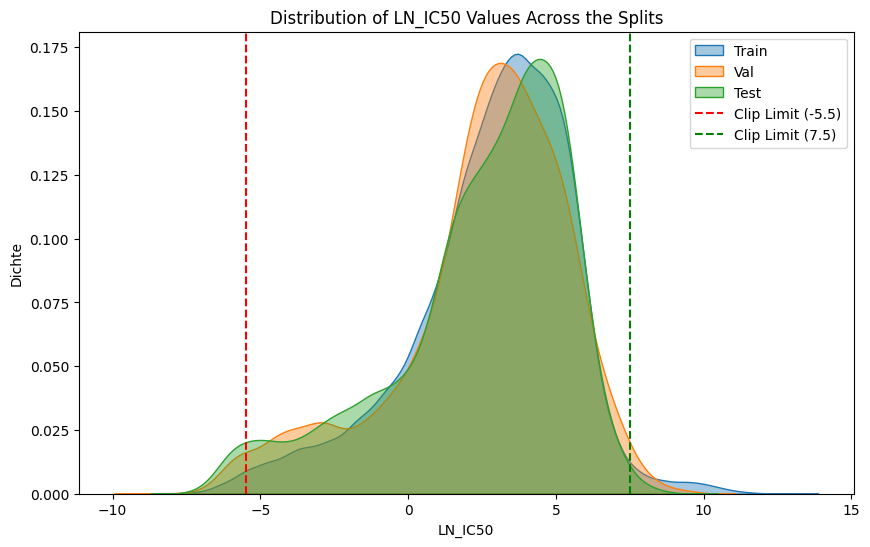

In [99]:
y_train_check = y_flat[idx_train]
y_val_check = y_flat[idx_val]
y_test_check = y_flat[idx_test]

print(f"Mean Train: {y_train_check.mean():.3f}")
print(f"Mean Val:   {y_val_check.mean():.3f}")
print(f"Mean Test:  {y_test_check.mean():.3f}")

data_to_plot = {'Train': y_train_check, 'Val': y_val_check, 'Test': y_test_check}

plt.figure(figsize=(10, 6))
for label, data in data_to_plot.items():
    sns.kdeplot(data, label=label, fill=True, alpha=0.4)
plt.axvline(x=-5.5, color='red', linestyle='--', label='Clip Limit (-5.5)')
plt.axvline(x=7.5, color='green', linestyle='--', label='Clip Limit (7.5)')
plt.title('Distribution of LN_IC50 Values Across the Splits')
plt.xlabel('LN_IC50')
plt.ylabel('Dichte')
plt.legend()
plt.show()

In [100]:
'''df = pd.DataFrame({'drug_group': np.array(drug_groups).flatten(),'LN_IC50': np.array(y_raw).flatten()})
drug_stats = df.groupby('drug_group')['LN_IC50'].agg(['mean', 'std', 'count', 'min', 'max']).reset_index()
drug_stats_sorted = drug_stats.sort_values(by='mean')
print("=== Medications with the lowest values ===")
print(drug_stats_sorted.head(10))
print("\n=== Medications with the highest values ===")
print(drug_stats_sorted.tail(10))'''

'df = pd.DataFrame({\'drug_group\': np.array(drug_groups).flatten(),\'LN_IC50\': np.array(y_raw).flatten()})\ndrug_stats = df.groupby(\'drug_group\')[\'LN_IC50\'].agg([\'mean\', \'std\', \'count\', \'min\', \'max\']).reset_index()\ndrug_stats_sorted = drug_stats.sort_values(by=\'mean\')\nprint("=== Medications with the lowest values ===")\nprint(drug_stats_sorted.head(10))\nprint("\n=== Medications with the highest values ===")\nprint(drug_stats_sorted.tail(10))'

### Graphs

In [104]:
import os
cache_path = '/Users/lukasrasche/Desktop/masterthesis/processed_graph_cache.pt'
bool = False
# Helper function for building PyG datasets
if bool and os.path.exists(cache_path):
    print("Load graphs from Storage...")
    graph_cache = torch.load(cache_path, weights_only=False)
else:
    unique_smiles = np.unique(smiles_raw)
    print(f"Create a graph cache for {len(unique_smiles)} unique drugs...")
    graph_cache = {}
    for smiles in unique_smiles:
        graph_cache[smiles] = smiles_to_graph(smiles)
    #torch.save(graph_cache, cache_path)
    #print("Cache saved successfully!")

print("Building PyG Graphs...")
train_dataset = build_pyg_dataset(smiles_raw[idx_train], X_gen_train, y_train, cache=graph_cache, use_cache=False) #########
val_dataset = build_pyg_dataset(smiles_raw[idx_val], X_gen_val, y_val, cache=graph_cache, use_cache=False)
test_dataset = build_pyg_dataset(smiles_raw[idx_test], X_gen_test, y_test_orig, cache=graph_cache, use_cache=False)
print(f"Graph Datasets: Train={len(train_dataset)}, Val={len(val_dataset)}, Test={len(test_dataset)}")

# Create PyG DataLoaders (these automatically load the variable graphs onto the GPU at runtime)
# für Mac pin_memory=False, da sonst Fehler auftreten
g = torch.Generator()
g.manual_seed(101)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=False, pin_memory=False, generator=g)
train_eval_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False, drop_last=False, pin_memory=False)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, pin_memory=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, pin_memory=False)

Create a graph cache for 229 unique drugs...
Building PyG Graphs...
Graph Datasets: Train=116092, Val=14247, Test=13743


### Seed evaluation

In [91]:
#seeds = [101]
# Forces the file to be re-read from memory
importlib.reload(gnn_models_utils)
from gnn_models_utils import GroundedCrossAttentionModel

In [105]:
def fit_and_score(gene_token_indices):
    # get checkpoint path for MolCLR model
    molclr_dir = Path("../MolCLR").resolve()
    checkpoint_path = molclr_dir / "ckpt" / "pretrained_gcn" / "checkpoints" / "model.pth"
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"MolCLR checkpoint not found: {checkpoint_path}")

    seed_results = []
    amp_enabled = device.type in ("cuda","mps")
    scaler = torch.amp.GradScaler(device.type, enabled=False)

    for run_idx, seed in enumerate(seeds):
        print(f"\n==========================================")
        print(f"Seed {run_idx + 1}/{len(seeds)} (Seed-value: {seed}), GNN-Type: {gnn_type}")
        print(f"==========================================")

        set_seed(seed)
        #torch.use_deterministic_algorithms(True, warn_only=True)
        train_loader.generator.manual_seed(seed)

        molclr_gcn = GCN(num_layer=5, emb_dim=300, feat_dim=512, drop_ratio=0, pool="mean").to(device)
        state_dict = torch.load(checkpoint_path, map_location=device, weights_only=True)
        molclr_gcn.load_state_dict(state_dict, strict=True)

        model = GroundedCrossAttentionModel(
            gene_token_indices=gene_token_indices,
            hidden_dim=hidden_dim,
            num_heads=4,
            dropout=dropout,
            gnn_type=gnn_type,
            molclr_backbone=molclr_gcn,
            freeze_molclr=freeze_bool
        ).to(device)

        #criterion = weighted_mse_loss  # custom loss function
        #criterion = nn.HuberLoss(delta=1.0) # mit RobustScaler zusammen
        criterion = nn.MSELoss()

        # differential learning rates
        if freeze_bool:
            regressor_params = []
            other_params = []
            for name, param in model.named_parameters():
                if "regressor" in name:
                    regressor_params.append(param)
                else:
                    other_params.append(param)
                    
            optimizer = optim.AdamW([
                {'params': other_params, 'lr': lr},
                {'params': regressor_params, 'lr': lr * 5}  # higher learning rate for regression head
            ], weight_decay=weight_decay)
        else:
            molclr_params = []
            regressor_params = []
            other_params = []
            for name, param in model.named_parameters():
                if "drug_encoder" in name:
                    molclr_params.append(param)
                elif "regressor" in name:
                    regressor_params.append(param)
                else:
                    other_params.append(param)
            optimizer = torch.optim.AdamW([
                {'params': molclr_params, 'lr': 1e-6},    # Tiny LR: protects chemical knowledge
                {'params': other_params, 'lr': lr},    # Normal LR: fast learning of new layers
                {'params': regressor_params, 'lr': lr * 5, 'weight_decay': 0.0}
            ], weight_decay=weight_decay)

        best_val_loss = float("inf")
        best_epoch = -1
        model_checkpoint_path = f"best_model_seed_{seed}.pt"        
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=patience)
        early_stopping = EarlyStopping(patience=10, min_delta=0.001, path=model_checkpoint_path)

        train_loss_history = []
        val_loss_history = []
        train_eval_loss_history = []

        for epoch in range(epochs):
            model.train()
            if freeze_bool:
                model.drug_encoder.eval()
            train_loss = 0.0
            # Iterating Over the PyG DataLoader
            for batch in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs}", leave=False):
                batch = batch.to(device)
                optimizer.zero_grad(set_to_none=True)
                with torch.amp.autocast(device_type=device.type, enabled=False):
                    # The model receives the genes and the ENTIRE GraphBatch object
                    preds = model(batch.gene, batch)
                    loss = criterion(preds.squeeze(-1), batch.y_true.squeeze(-1))
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # Gradient Clipping
                scaler.step(optimizer)
                scaler.update()
                train_loss += loss.item() * batch.num_graphs

            mean_train_loss = train_loss / len(train_dataset)

            # Fast Validation
            model.eval()
            train_eval_loss = 0.0
            val_loss = 0.0
            with torch.no_grad():
                for batch in train_eval_loader:
                    batch = batch.to(device)
                    with torch.amp.autocast(device_type=device.type, enabled=False):
                        preds = model(batch.gene, batch)
                        loss = criterion(
                            preds.squeeze(-1),
                            batch.y_true.squeeze(-1)
                        )
                    train_eval_loss += loss.item() * batch.num_graphs
                for batch in val_loader:
                    batch = batch.to(device)
                    with torch.amp.autocast(device_type=device.type, enabled=False):
                        preds = model(batch.gene, batch)
                        loss = criterion(preds.squeeze(-1), batch.y_true.squeeze(-1))
                    val_loss += loss.item() * batch.num_graphs

            mean_val_loss = val_loss / len(val_dataset)
            mean_train_eval_loss = train_eval_loss / len(train_dataset)
            train_loss_history.append(mean_train_loss)
            val_loss_history.append(mean_val_loss)
            train_eval_loss_history.append(mean_train_eval_loss)

            if mean_val_loss < best_val_loss:
                best_val_loss = mean_val_loss
                best_epoch = epoch + 1
                torch.save(model.state_dict(), model_checkpoint_path)

            scheduler.step(mean_val_loss)
            early_stopping(mean_val_loss, model)
            if early_stopping.early_stop:
                print("Early stopping! Training is ending.")
                break

        plt.figure(figsize=(8, 5))
        plt.plot(range(1, len(train_loss_history) + 1), train_loss_history, label='Train Loss (MSE)', marker='o', markersize=4)
        plt.plot(range(1, len(val_loss_history) + 1), val_loss_history, label='Val Loss (MSE)', marker='o', markersize=4, color='orange')
        plt.plot(range(1, len(train_eval_loss_history) + 1), train_eval_loss_history, label='Train Eval Loss (MSE)', marker='o', markersize=4, color='green')
        plt.xlabel('Epochen')
        plt.ylabel('Loss')
        plt.title(f'Learning curve: seed {seed} (hidden dim: {hidden_dim})')
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.show()

        # Test Evaluation
        model.load_state_dict(torch.load(model_checkpoint_path, weights_only=True))
        model.eval()

        test_preds_list = []
        with torch.no_grad():
            for i, batch in enumerate(test_loader):
                batch = batch.to(device)
                with torch.amp.autocast(device_type=device.type, enabled=False):
                    # Attention save on the first batch
                    preds = model(batch.gene, batch, save_attention=(i==0))
                test_preds_list.append(preds.cpu())

        test_preds_orig = torch.cat(test_preds_list).numpy()
        test_preds_orig = y_scaler.inverse_transform(test_preds_orig.reshape(-1, 1)).flatten()

        test_rmse = root_mean_squared_error(y_test_orig, test_preds_orig)
        test_r2 = r2_score(y_test_orig, test_preds_orig)
        test_mae = mean_absolute_error(y_test_orig, test_preds_orig)
        test_pearson_corr, p_value_pearson = pearsonr(y_test_orig, test_preds_orig)
        test_spearman_corr, p_value_spearman = spearmanr(y_test_orig, test_preds_orig)
        #test_c_index = concordance_index(y_test_orig, test_preds_orig)

        print(f"--> Result Seed {seed}: Best Epoch: {best_epoch:02d} | Val Loss: {best_val_loss:.4f} | Test RMSE: {test_rmse:.4f} | Test R²: {test_r2:.4f}")

        seed_results.append({
            "seed": seed,
            "best_epoch": best_epoch,
            "val_loss": best_val_loss,
            "test_rmse": test_rmse,
            "test_r2": test_r2,
            "test_mae": test_mae,
            "test_pearson_corr": test_pearson_corr,
            "test_spearman_corr": test_spearman_corr#,
            #"test_c_index": test_c_index
        })

        # save model + target values + predictions
        checkpoint = {
            "state_dict": model.state_dict(),
            "y_true": torch.tensor(y_test_orig),
            "y_pred": torch.tensor(test_preds_orig),
        }
        torch.save(checkpoint, model_checkpoint_path)

    df_results = pd.DataFrame(seed_results)
    print("\n" + "="*50)
    print("Analysis of all seeds")
    print("="*50)
    print(df_results.to_string(index=False))
    print("\n--- Aggregated metrics (mean ± std) ---")
    print(f"Test RMSE: {df_results['test_rmse'].mean():.4f} ± {df_results['test_rmse'].std():.4f}")
    print(f"Test R²:   {df_results['test_r2'].mean():.4f} ± {df_results['test_r2'].std():.4f}")
    print(f"Test Spearman coefficient: {df_results['test_spearman_corr'].mean():.4f} ± {df_results['test_spearman_corr'].std():.4f}")
    print(f"Test Pearson coefficient: {df_results['test_pearson_corr'].mean():.4f} ± {df_results['test_pearson_corr'].std():.4f}")
    print(f"Test mean absolute error: {df_results['test_mae'].mean():.4f} ± {df_results['test_mae'].std():.4f}")
    print("\n" + "="*50 + "\n")

    return best_val_loss, test_preds_orig


Seed 1/1 (Seed-value: 101), GNN-Type: GCN
Using pre-trained MolCLR backbone for drug encoding.
Freezing MolCLR backbone parameters.


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 1 out of 10


EarlyStopping counter: 2 out of 10


EarlyStopping counter: 3 out of 10


EarlyStopping counter: 4 out of 10


... (2 outputs left out)

EarlyStopping counter: 7 out of 10


EarlyStopping counter: 8 out of 10


EarlyStopping counter: 9 out of 10


EarlyStopping counter: 10 out of 10
Early stopping! Training is ending.


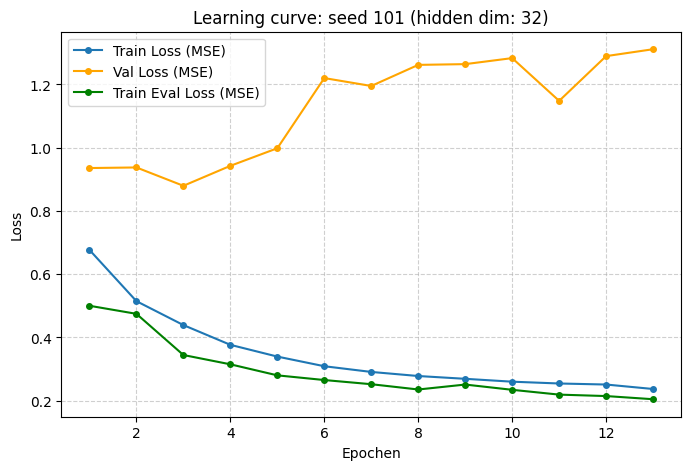

--> Result Seed 101: Best Epoch: 03 | Val Loss: 0.8795 | Test RMSE: 2.0501 | Test R²: 0.5246

Analysis of all seeds
 seed  best_epoch  val_loss  test_rmse  test_r2  test_mae  test_pearson_corr  test_spearman_corr
  101           3  0.879542   2.050127 0.524594  1.614556           0.772285            0.654724

--- Aggregated metrics (mean ± std) ---
Test RMSE: 2.0501 ± nan
Test R²:   0.5246 ± nan
Test Spearman coefficient: 0.6547 ± nan
Test Pearson coefficient: 0.7723 ± nan
Test mean absolute error: 1.6146 ± nan




In [106]:
best_val_loss, test_preds_orig = fit_and_score(gene_token_indices)

## Optuna for automatic finetuning

In [52]:
import optuna
import random
from torch_geometric.loader import DataLoader

sample_fraction = 1
# get checkpoint path for MolCLR model
molclr_dir = Path("../MolCLR").resolve()
checkpoint_path = molclr_dir / "ckpt" / "pretrained_gcn" / "checkpoints" / "model.pth"
amp_enabled = device.type in ("cuda","mps")
scaler = torch.amp.GradScaler(device.type, enabled=False)
pruner = optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=10)

random.seed(101)
optuna_train_dataset = random.sample(train_dataset, int(len(train_dataset) * sample_fraction))
optuna_val_dataset = random.sample(val_dataset, int(len(val_dataset) * sample_fraction))

def objective(trial):
    # Parameter Search Space
    hidden_dim = trial.suggest_categorical("hidden_dim", [32, 64])
    lr = trial.suggest_float("lr", 1e-5, 1e-3, log=True)
    dropout = trial.suggest_float("dropout", 0.2, 0.5)
    batch_size = trial.suggest_categorical("batch_size", [64, 128, 256])
    num_heads = trial.suggest_categorical("num_heads", [2,4,8])
    
    trial_train_loader = DataLoader(optuna_train_dataset, batch_size=batch_size, shuffle=True, drop_last=False)
    trial_val_loader = DataLoader(optuna_val_dataset, batch_size=batch_size, shuffle=False)

    molclr_gcn = GCN(num_layer=5, emb_dim=300, feat_dim=512, drop_ratio=0, pool="mean").to(device)
    state_dict = torch.load(checkpoint_path, map_location=device, weights_only=True)
    molclr_gcn.load_state_dict(state_dict, strict=True)
    model = GroundedCrossAttentionModel(
        gene_token_indices=gene_token_indices,
        hidden_dim=hidden_dim,
        num_heads=num_heads,
        dropout=dropout,
        gnn_type="GCN",
        molclr_backbone=molclr_gcn, 
        freeze_molclr=False
    ).to(device)
    
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-3)
    criterion = torch.nn.MSELoss()
    
    best_val_loss = float("inf")
    
    # 15 epochs are usually more than enough for an Optuna search
    for epoch in range(15):
        model.train()
        for batch in trial_train_loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            
            with torch.amp.autocast(device_type=device.type, enabled=False):
                preds = model(batch.gene, batch)
                loss = criterion(preds.squeeze(-1), batch.y_true.squeeze(-1))
                
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            
        # Validation
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch in trial_val_loader:
                batch = batch.to(device)
                with torch.amp.autocast(device_type=device.type, enabled=False):
                    preds = model(batch.gene, batch)
                    loss = criterion(preds.squeeze(-1), batch.y_true.squeeze(-1))
                val_loss += loss.item() * batch.num_graphs
                
        mean_val_loss = val_loss / len(optuna_val_dataset)
        if mean_val_loss < best_val_loss:
            best_val_loss = mean_val_loss
            
        # Tell Optuna what the current loss is (to cut short pointless runs early on)
        trial.report(mean_val_loss, epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return best_val_loss

study = optuna.create_study(direction="minimize", pruner=pruner)
print(f"Start a search on {len(optuna_train_dataset)} training graphs....")

study.optimize(objective, n_trials=20)

print("\n=== OPTUNA RESULTS ===")
print("Best Parameter:", study.best_params)
print("Best Val Loss:", study.best_value)

[I 2026-10-29 11:47:11,883] A new study created in memory with name: no-name-e3ad6910-3700-44c0-bd19-737eba209174


Start a search on 116092 training graphs....
Using pre-trained MolCLR backbone for drug encoding.


[I 2026-10-29 12:08:20,585] Trial 0 finished with value: 0.8980473156032909 and parameters: {'hidden_dim': 32, 'lr': 0.0002019358457819015, 'dropout': 0.3515804586481071, 'batch_size': 128, 'num_heads': 2}. Best is trial 0 with value: 0.8980473156032909.


Using pre-trained MolCLR backbone for drug encoding.


[I 2026-10-29 12:30:05,477] Trial 1 finished with value: 0.6954351733456647 and parameters: {'hidden_dim': 64, 'lr': 0.0005645973594086961, 'dropout': 0.48549152043632, 'batch_size': 128, 'num_heads': 2}. Best is trial 1 with value: 0.6954351733456647.


Using pre-trained MolCLR backbone for drug encoding.


... (32 outputs left out)

[I 2026-10-29 21:57:40,059] Trial 18 finished with value: 0.6197335263038924 and parameters: {'hidden_dim': 32, 'lr': 0.0005313322168980652, 'dropout': 0.25510202933365955, 'batch_size': 256, 'num_heads': 4}. Best is trial 18 with value: 0.6197335263038924.


Using pre-trained MolCLR backbone for drug encoding.


[I 2026-10-29 22:13:18,159] Trial 19 finished with value: 0.696262107394474 and parameters: {'hidden_dim': 32, 'lr': 0.0008554959488086095, 'dropout': 0.25873841700757905, 'batch_size': 256, 'num_heads': 8}. Best is trial 18 with value: 0.6197335263038924.



=== OPTUNA RESULTS ===
Best Parameter: {'hidden_dim': 32, 'lr': 0.0005313322168980652, 'dropout': 0.25510202933365955, 'batch_size': 256, 'num_heads': 4}
Best Val Loss: 0.6197335263038924


## Residuals plot and other stuff

### Load model
To load model again, model class has to be present + initialise model with exact same parameters as in training

In [30]:
molclr_gcn = GCN(num_layer=5, emb_dim=300, feat_dim=512, drop_ratio=0, pool="mean").to(device)
molclr_dir = Path("../MolCLR").resolve()
checkpoint_path = molclr_dir / "ckpt" / "pretrained_gcn" / "checkpoints" / "model.pth"
state_dict = torch.load(checkpoint_path, map_location=device, weights_only=True)
molclr_gcn.load_state_dict(state_dict, strict=True)

model = GroundedCrossAttentionModel(
    gene_token_indices=gene_token_indices,
    hidden_dim=hidden_dim,
    num_heads=4,
    dropout=dropout,
    gnn_type=gnn_type,
    molclr_backbone=molclr_gcn,
    freeze_molclr=False
).to(device)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
# künftig so:
#checkpoint = torch.load(model_checkpoint_path, map_location=device, weights_only=True)
#model.load_state_dict(checkpoint["state_dict"])
#y_true = checkpoint["y_true"]
#y_pred = checkpoint["y_pred"]
state_dict = torch.load("best_model_seed_101.pt", map_location=device, weights_only=True)
model.load_state_dict(state_dict)
model.eval()

Using pre-trained MolCLR backbone for drug encoding.


GroundedCrossAttentionModel(
  (gene_encoder): ModularTokenEncoder(
    (projections): ModuleList(
      (0): Sequential(
        (0): Linear(in_features=93, out_features=64, bias=True)
        (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (2): ReLU()
        (3): Dropout(p=0.3, inplace=False)
      )
      (1): Sequential(
        (0): Linear(in_features=74, out_features=64, bias=True)
        (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (2): ReLU()
        (3): Dropout(p=0.3, inplace=False)
      )
      (2): Sequential(
        (0): Linear(in_features=30, out_features=64, bias=True)
        (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (2): ReLU()
        (3): Dropout(p=0.3, inplace=False)
      )
    )
  )
  (drug_encoder): GCN(
    (x_embedding1): Embedding(119, 300)
    (x_embedding2): Embedding(3, 300)
    (gnns): ModuleList(
      (0-4): 5 x GCNConv()
    )
    (batch_norms): ModuleLis

### Residual plot

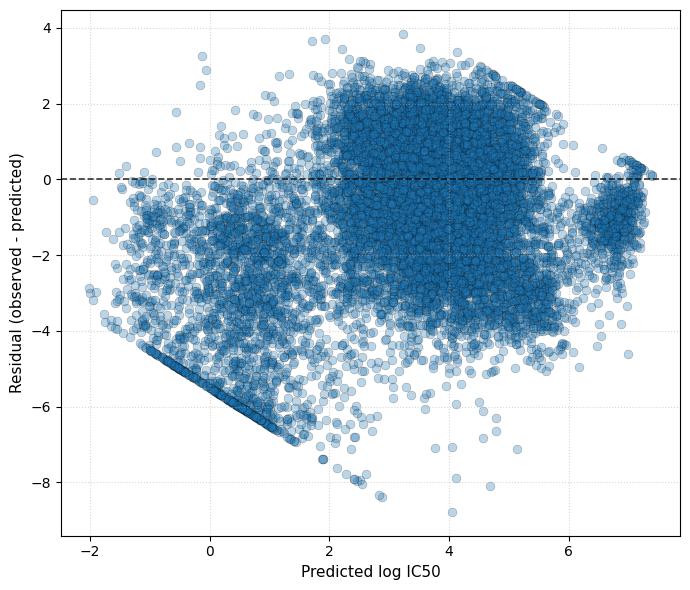

In [103]:
residuals = y_test_orig - test_preds_orig
rmse_val = root_mean_squared_error(y_test_orig, test_preds_orig)
r2_val = r2_score(y_test_orig, test_preds_orig)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(test_preds_orig, residuals, color='#1f77b4', alpha=0.3, s=40, edgecolors='black', linewidth=0.4, marker = 'o')
ax.axhline(0, color='black', linestyle='--', linewidth=1.2, alpha=0.8)

ax.set_xlabel("Predicted log IC50", fontsize=11)
ax.set_ylabel("Residual (observed - predicted)", fontsize=11)
ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
#plt.savefig("residuals_vs_predicted.png", bbox_inches='tight')
plt.show()

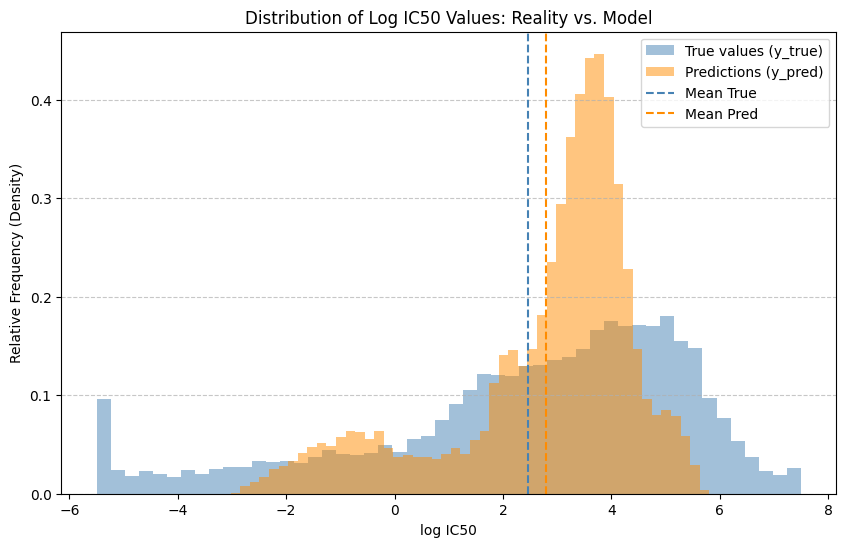

In [24]:
import matplotlib.pyplot as plt
import numpy as np

y_true = y_test_orig
y_pred = test_preds_orig

plt.figure(figsize=(10, 6))

plt.hist(y_true, bins=50, alpha=0.5, label='True values (y_true)', color='steelblue', density=True)
plt.hist(y_pred, bins=50, alpha=0.5, label='Predictions (y_pred)', color='darkorange', density=True)
plt.axvline(np.mean(y_true), color='steelblue', linestyle='dashed', linewidth=1.5, label='Mean True')
plt.axvline(np.mean(y_pred), color='darkorange', linestyle='dashed', linewidth=1.5, label='Mean Pred')

plt.title('Distribution of Log IC50 Values: Reality vs. Model')
plt.xlabel('log IC50')
plt.ylabel('Relative Frequency (Density)')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Other stuff

In [25]:
import pandas as pd

check_df = pd.DataFrame({
    'drug_id': drug_groups[idx_test],
    'y_true': y_test_orig,
    'y_pred': test_preds_orig,
    'residual': y_test_orig - test_preds_orig
})

# Calculate the mean residual per active ingredient
drug_summary = check_df.groupby('drug_id').agg(
    n_samples=('residual', 'count'),
    mean_residual=('residual', 'mean'),
    mean_true=('y_true', 'mean'),
    mean_pred=('y_pred', 'mean')
).sort_values('mean_residual')

print("Top 5 active ingredients with the most harmful residues:")
print(drug_summary.head(5))

Top 5 active ingredients with the most harmful residues:
         n_samples  mean_residual  mean_true  mean_pred
drug_id                                                
1191           706      -6.859329  -3.289043   3.570287
1936           706      -5.296530  -0.177886   5.118644
1809           554      -5.042986  -1.095963   3.947023
1237           712      -1.782927   0.855468   2.638395
1009           136      -1.547133   0.689731   2.236863


You can see that these outliers in residuals plot stem mainly from two/three drugs (in average)

In [26]:
extreme_drug_ids = ["1911", "1248", "1372"]
outlier_names = df[df['DRUG_ID'].isin(extreme_drug_ids)][['DRUG_ID', 'DRUG_NAME']].drop_duplicates()
print(outlier_names)

    DRUG_ID     DRUG_NAME
97     1372    Trametinib
465    1248     Daporinad
774    1911  Dactinomycin



Gene -> Drug
Shape: (3, 36)
Min: 0.021445533
Max: 0.03764927
Mean: 0.02777778
NaNs: 0
Sum per query (first 5): [1.0000001 1.0000001 1.       ]

Drug -> Gene
Shape: (36, 3)
Min: 0.32085103
Max: 0.3543663
Mean: 0.33333334
NaNs: 0
Sum per query (first 5): [1.         0.99999994 1.         1.         1.        ]


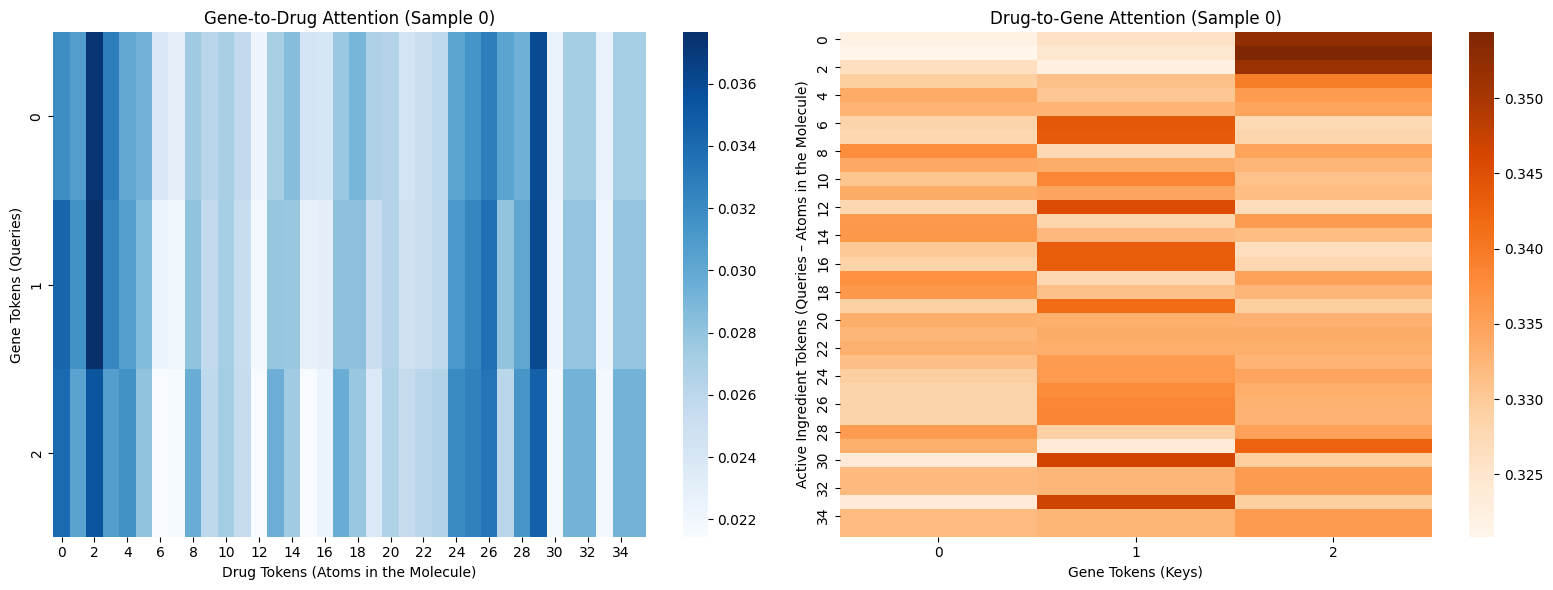

In [24]:
importlib.reload(gnn_models_utils)
from gnn_models_utils import plot_attention_weights

plot_attention_weights(model, test_loader, device, sample_idx=0)

### Drawing

The molecule in Sample 100 has exactly 33 atoms.
SMILES: CC(C)S(=O)(=O)C1=CC=C(C=C1)C2=CN=C(C(=N2)C3=CC(=NO3)C4=CC=C(C=C4)CNC)N


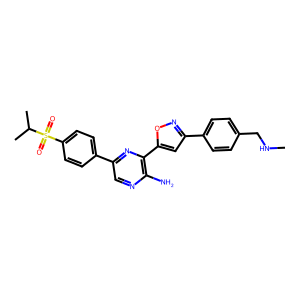

In [31]:
from rdkit.Chem import Draw
# Reload the PyG batch object to check the SMILES strings and names
sample = 100
batch = next(iter(test_loader))
num_real_atoms = batch.ptr[sample+1] - batch.ptr[sample]
print(f"The molecule in Sample {sample} has exactly {num_real_atoms.item()} atoms.")

smiles_of_sample_0 = smiles_raw[idx_test][sample]
mol = Chem.MolFromSmiles(smiles_of_sample_0)
print(f"SMILES: {smiles_of_sample_0}")
img = Draw.MolToImage(mol)
display(img)

Visualizing Attention for SMILES: CC(C)S(=O)(=O)C1=CC=C(C=C1)C2=CN=C(C(=N2)C3=CC(=NO3)C4=CC=C(C=C4)CNC)N
Number of atoms: 33


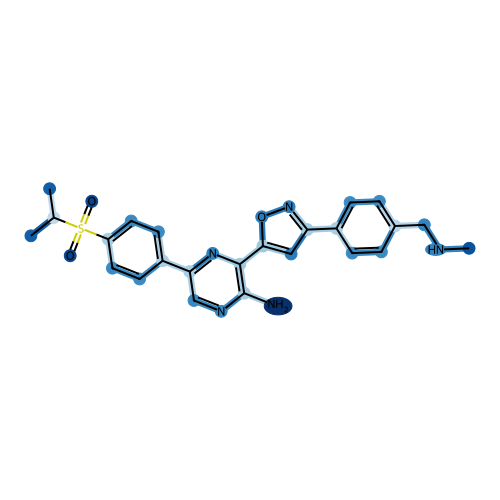

In [30]:
from gnn_models_utils import visualize_atom_attention
batch = next(iter(test_loader))
num_real_atoms_sample = (batch.ptr[sample+1] - batch.ptr[sample]).item()
smiles_sample = smiles_raw[idx_test][sample]

attn_dict = model.last_attn_weights
gene_to_drug_attn = attn_dict["gene_to_drug"][sample]

print(f"Visualizing Attention for SMILES: {smiles_sample}")
print(f"Number of atoms: {num_real_atoms_sample}")
visualize_atom_attention(smiles_sample, gene_to_drug_attn, num_real_atoms_sample)

### Standard deviation across attention

Samples analyzed in the test set: 13743
Moderate correlation between samples: 0.6145
Number of gene tokens: 54
Number of drug tokens: 54
Maximum standard deviation (gene-to-drug): 0.0201
Maximum standard deviation (drug-to-gene): 0.0191


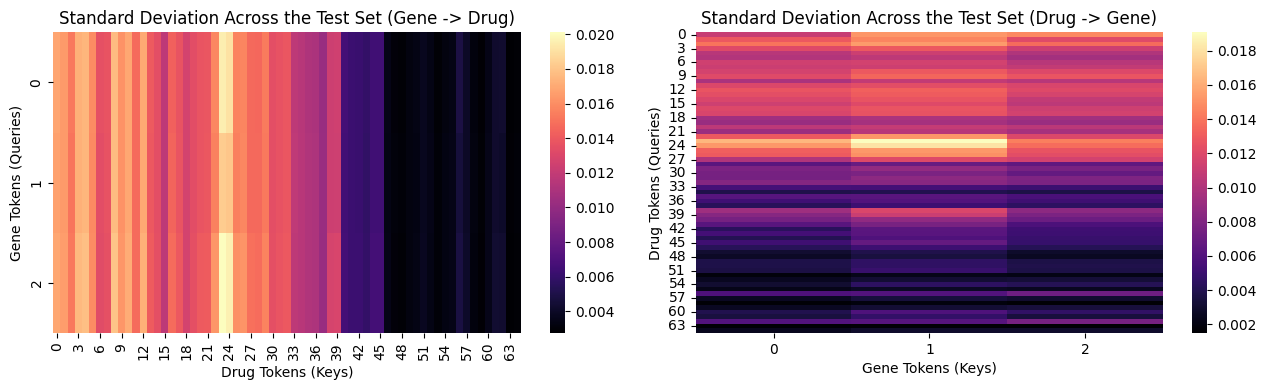

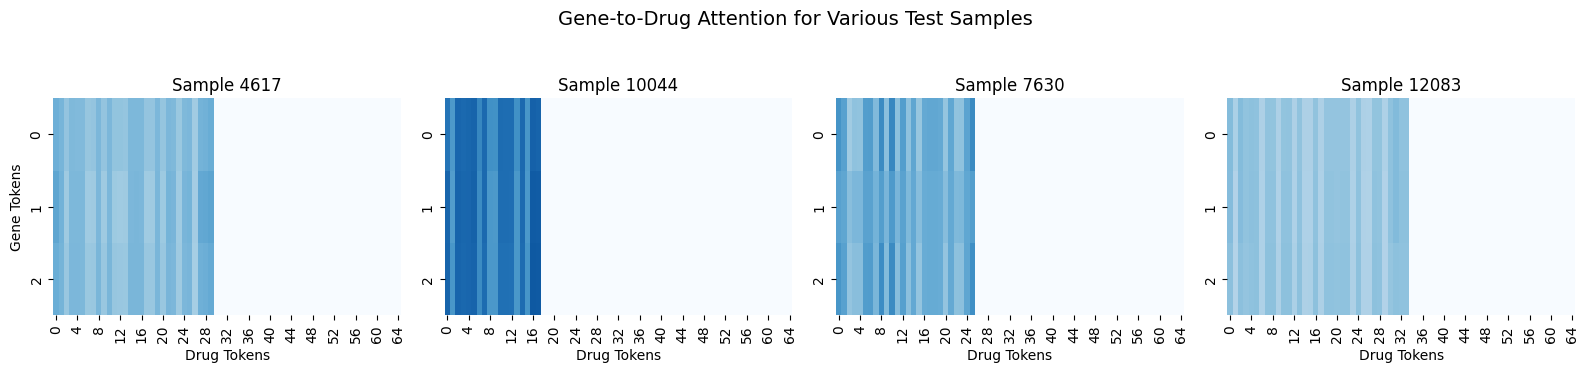

In [32]:
importlib.reload(gnn_models_utils)
from gnn_models_utils import evaluate_attention_diversity

evaluate_attention_diversity(model, test_loader, device)

-> attention collapse would mean correlation~1 and standard deviation~0 \
so no attention collapse \
drug-to-gene shows homogeneity, means model couldn't use drug for more information about genes

## Overlap between drugs with structural similarity (global) and functional groups (local)

A. 2D Density & Correlation Analysis (Scatter / Hexbin Plot): Plot $S_{\text{struct}}$ on the X-axis and $S_{\text{FG}}$ on the Y-axis for all active ingredient pairs. Since there are $N \times (N-1) / 2$ pairs, use a hexbin or KDE plot: Calculate the Spearman rank correlation $r_s$ between the two matrices (or perform a Mantel test).

B. Quadrant Analysis (Identification of Scaffold Hops) Set thresholds (e.g., $S_{\text{struct}} \ge 0{,}5$ and $S_{\text{FG}} \ge 0{,}7$) and divide the pairs into four quadrants: High Structure + High FG: Classic chemical analogs/series. Low Structure + High FG (Scaffold Hops): Compounds with completely different scaffolds but identical functional groups. Particularly biologically relevant for your master’s thesis, as they often bind to similar targets. High Structure + Low FG: Structurally related molecules in which key groups have been substituted (potential activity cliffs).

C. $k$-NN Jaccard Overlap (Local Neighborhoods) Determine the top $k$ most similar partners for each molecule based on structure ($N_{\text{struct}}^{(k)}$) and based on functional groups ($N_{\text{FG}}^{(k)}$). $$\text{Overlap}(m) = \frac{\vert{}N_{\text{struct}}^{(k)}(m) \cap N_{\text{FG}}^{(k)}(m)\vert{}}{\vert{}N_{\text{struct}}^{(k)} (m) \cup N_{\text{FG}}^{(k)}(m)\vert{}}$$A low average overlap indicates that functional groups span different similarity spaces than 2D fingerprints.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem, Fragments

# Load SMILES and unique molecules
unique_drugs = df.drop_duplicates(subset=['DRUG_ID']).copy()
smiles_list = unique_drugs['SMILES'].tolist()
mols = [Chem.MolFromSmiles(s) for s in smiles_list]

# Calculate structural similarity (Morgan Fingerprints -> Tanimoto)
fps = [AllChem.GetMorganFingerprintAsBitVect(m, 2, nBits=1024) for m in mols]
n_mols = len(mols)

struct_sim_matrix = np.zeros((n_mols, n_mols))
for i in range(n_mols):
    sims = DataStructs.BulkTanimotoSimilarity(fps[i], fps)
    struct_sim_matrix[i] = sims

# Calculate the similarity of functional groups (Jaccard on RDKit fragments)
frag_funcs = [func for name, func in Fragments.__dict__.items() if name.startswith('fr_')]
frag_counts = np.array([[func(m) > 0 for func in frag_funcs] for m in mols], dtype=bool)

# Jaccard Distance (1 – Jaccard Similarity)
fg_dist_matrix = squareform(pdist(frag_counts, metric='jaccard'))
fg_sim_matrix = 1.0 - fg_dist_matrix
np.fill_diagonal(fg_sim_matrix, 1.0)

# Extract the upper triangular matrix (only unique pairs where i < j)
triu_idx = np.triu_indices(n_mols, k=1)
s_struct = struct_sim_matrix[triu_idx]
s_fg = fg_sim_matrix[triu_idx]

# Calculate Correlation
corr, p_val = spearmanr(s_struct, s_fg)
print(f"Spearman Correlation: {corr:.4f} (p = {p_val:.2e})")

# Visualization & Quadrant Analysis
plt.figure(figsize=(8, 6))
hb = plt.hexbin(s_struct, s_fg, gridsize=40, cmap='viridis', mincnt=1, bins='log')
plt.colorbar(hb, label='Log10(Number of pairs)')
plt.axvline(x=0.5, color='red', linestyle='--', alpha=0.7)
plt.axhline(y=0.7, color='red', linestyle='--', alpha=0.7)

plt.xlabel("Global Structural Similarity (Morgan Tanimoto)")
plt.ylabel("Functional Group Similarity (Jaccard)")
plt.title(f"Structural- vs. FG-Similarity (Spearman r = {corr:.2f})")
plt.tight_layout()
plt.show()

# Filter scaffold hops (low structural similarity but identical functional groups)
scaffold_hops = np.where((s_struct < 0.3) & (s_fg > 0.8))[0]
print(f"Scaffold-hop candidate pairs found: {len(scaffold_hops)}")

In [ ]:
from rdkit.Chem import Draw

# Resolve the indices of the scaffold-hop pairs
hop_pairs = [(triu_idx[0][i], triu_idx[1][i]) for i in scaffold_hops]

# Show the Top 3 Couples
display_mols = []
legends = []

for idx1, idx2 in hop_pairs[:3]:
    d1 = unique_drugs.iloc[idx1]
    d2 = unique_drugs.iloc[idx2]

    display_mols.extend([mols[idx1], mols[idx2]])
    legends.extend([
        f"{d1['DRUG_NAME']} (ID:{d1['DRUG_ID']})",
        f"{d2['DRUG_NAME']} (ID:{d2['DRUG_ID']})"
    ])

#img =
Draw.MolsToGridImage(display_mols, molsPerRow=2, subImgSize=(300, 200), legends=legends)
#img.save("scaffold_hops_examples.png")

## Research gene tokens

In [97]:
import gseapy as gp
import pandas as pd

# get gene names from one token X
token_index = 0  # Change this to the desired token index (0, 1, or 2)
df_genomic = df.filter(regex=r'.* \(.*\)')
raw_genes = df_genomic.columns[gene_token_indices[token_index]].tolist()
clean_gene_list = [gene.split(' ')[0] for gene in raw_genes]
print(f"Number of genes in Token {token_index}: {len(clean_gene_list)}")

# Run the enrichment analysis using the Enrichr API
enr_results = gp.enrichr(
    gene_list=clean_gene_list, # Liste der Gene
    gene_sets=['KEGG_2021_Human', 'GO_Biological_Process_2026'], # databases to query
    organism='human', 
    outdir=None # Set a path if you want to save the results
)

df_results = enr_results.results
# Filter by significant pathways (Adjusted p-value < 0.05)
significant_pathways = df_results[df_results['Adjusted P-value'] < 0.05].reset_index(drop=True)
print(significant_pathways[['Term', 'Overlap', 'Adjusted P-value']].head(10))

Number of genes in Token 0: 22
                                                Term Overlap  Adjusted P-value
0      Actin Filament Network Formation (GO:0051639)    2/12          0.024459
1  Positive Regulation of Sprouting Angiogenesis ...    2/19          0.025367
2         Establishment of Skin Barrier (GO:0061436)    2/21          0.025367
3            Skin Epidermis Development (GO:0098773)    2/24          0.025367
4           Regulation of Cell Adhesion (GO:0030155)   3/142          0.031575
5  Cellular Response to Hydrogen Peroxide (GO:007...    2/36          0.038295
6  Regulation of Sprouting Angiogenesis (GO:1903670)    2/40          0.040532
7         Response to Hydrogen Peroxide (GO:0042542)    2/43          0.040976


In [55]:
import numpy as np

# all used gene indices from all tokens
used_indices = np.concatenate(gene_token_indices)
all_indices = np.arange(len(df_genomic.columns))

# filter unuesed indices
unused_indices = np.setdiff1d(all_indices, used_indices)
raw_noise_genes = df_genomic.columns[unused_indices].tolist()
clean_noise_genes = [gene.split(' ')[0] for gene in raw_noise_genes]
print(f"Number of genes excluded: {len(clean_noise_genes)}")

# enricher
import gseapy as gp
enr_noise_results = gp.enrichr(
    gene_list=clean_noise_genes,             
    gene_sets=['KEGG_2021_Human', 'GO_Biological_Process_2021'], 
    organism='human', 
    outdir=None 
)
df_noise_results = enr_noise_results.results
significant_noise = df_noise_results[df_noise_results['Adjusted P-value'] < 0.05]
print("\nSignificant pathways in noise:")
print(significant_noise[['Term', 'Overlap', 'Adjusted P-value']].head(10))

Number of genes excluded: 781

Significant pathways in noise:
                                                Term Overlap  Adjusted P-value
0                                 Pathways in cancer  87/531      3.620292e-28
1                       Epstein-Barr virus infection  45/202      1.283623e-19
2                          Lipid and atherosclerosis  43/215      5.625943e-17
3                                  Colorectal cancer   28/86      6.813643e-17
4    Kaposi sarcoma-associated herpesvirus infection  40/193      1.538409e-16
5                           Chronic myeloid leukemia   26/76      1.948552e-16
6                             MAPK signaling pathway  49/294      2.473012e-16
7  AGE-RAGE signaling pathway in diabetic complic...  29/100      2.911994e-16
8                                        Hepatitis B  36/162      3.977628e-16
9            Human T-cell leukemia virus 1 infection  41/219      1.350960e-15
